# Olist Brazilian E-Commerce — Analytics Project
## Notebook 01 · Exploratory Data Analysis & Statistical Profiling

**Purpose:** Validate the four analytical datasets, profile their distributions, and freeze the statistical approach for Notebook 02.

**Notebook 02** performs hypothesis testing and business analysis; this notebook does not make business conclusions.

| Dataset | Grain | Main use |
|---|---|---|
| `seller_features` | Seller | Seller volume, risk and reliability |
| `order_delivery_features` | Order | Delivery durations and outcomes |
| `order_experience_features` | Order | Reviews and fulfillment experience |
| `customer_rfm_features` | Customer | Value and repeat behaviour |


## S1. Objectives & Business Purpose

### This notebook does
1. Validate **grain, keys, row counts, missingness and data types**.
2. Profile **distributions, concentration, skew and outliers**.
3. Check **group sizes and rate reliability**.
4. Freeze the **statistical methods and reporting rules** for Notebook 02.

### This notebook does not
- Run hypothesis tests.
- Make business recommendations.
- Build dashboard/storytelling visuals.

### Business questions protected
- **Seller risk:** Which seller rates are reliable enough to compare?
- **Delivery:** Which fulfillment stages and measures can be compared honestly?
- **Experience:** Can the data support detecting meaningful differences in satisfaction?
- **Customer value:** Is repeat purchasing common enough to support retention segmentation?

### Decision
Notebook 01 validates and profiles the data and freezes the statistical toolkit. Findings and recommendations are deferred to Notebook 02.


## S2. Analysis Configuration

The reproducibility settings, analytical parameters, and materiality thresholds used throughout this project are fixed here, before any data is loaded.
The materiality thresholds matter most. This dataset has roughly 100,000 orders, and at that size almost any difference becomes statistically significant. Agreeing beforehand what a *meaningful* difference looks like — in plain business terms — is what keeps Notebook 02 from reporting a trivial gap as a finding.

In [3]:
# ── Standard library ─────────────────────────────────────────────────────────
from datetime import datetime
from pathlib import Path

# ── Third-party ──────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

In [7]:
# ── Reproducibility ──────────────────────────────────────────────────────────
RANDOM_SEED = 42

# ── Distribution shape labels (S12) ──────────────────────────────────────────
SKEW_SYMMETRIC_MAX = 0.5
SKEW_MODERATE_MAX = 1.0

# ── High-cardinality grouping (S10) ──────────────────────────────────────────
# Categories with fewer units than this are collapsed into "other" before any
# group comparison, so no test runs on near-empty cells.
MIN_CATEGORY_SIZE = 30

# ── Materiality thresholds, pre-registered (rationale in the table below) ────
MATERIAL_REVIEW_GAP_STARS = 0.30
MATERIAL_RATE_DIFF_PP = 2.00
MATERIAL_LAST_MILE_DAYS = 1.00
MATERIAL_HANDOFF_HOURS = 12.00
MATERIAL_MONETARY_RELATIVE = 0.10
MATERIAL_CORRELATION_RHO = 0.20

# ── Data sources and paths (no credentials are stored in this notebook) ──────
BQ_PROJECT = "olist-analytics-500708"
BQ_DATASET = "olist_analytics"
DATA_DIR = Path(r"e:\reprompt-olist\reprompt\EDA\data").resolve()

In [5]:
# One seed drives every sample and bootstrap in this notebook. Randomness is
# always passed explicitly at the point of use, never taken from global state.
RNG = np.random.default_rng(RANDOM_SEED)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update(
    {
        "figure.figsize": (10, 5),
        "figure.dpi": 110,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.labelsize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
    }
)

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.4f}".format)

### Stated analytical policies

| Policy | Frozen decision |
|---|---|
| Preferred summary statistic | Median + IQR for skewed variables; mean reported alongside for comparison only |
| Preferred correlation method | Spearman (rank) — used throughout (S13) |
| Outlier policy | Detect and classify — never delete. Scope restricted to five continuous variables (S12) |
| Row-drop policy | No rows dropped, ever |
| Analysis date range | Full data for non-temporal analysis; restricted range for temporal analysis (frozen in S8) |
| Data snapshot | Local parquet copies with recorded load timestamp and row counts (S3) |

### Pre-registered materiality thresholds

These are **project-specific analyst-defined decision rules**, fixed before results are reviewed. They separate statistical significance from business significance.

| Metric | Threshold | Why this level |
|---|---|---|
| Review score gap | **≥ 0.30 stars** | Meaningful difference on a 1–5 customer-rating scale |
| Rate difference (anomaly / late / repeat) | **≥ 2.0 percentage points** | Meaningful absolute shift for low-frequency operational/customer outcomes |
| Last-mile duration | **≥ 1.0 day** | A full additional day represents a practical logistics difference |
| Handoff duration | **≥ 12 hours** | Half-day delay is a practical and actionable operational difference |
| Monetary difference | **≥ 10% relative** (median) | Large enough to represent a meaningful economic/value difference while limiting outlier influence |
| Correlation | **\|ρ\| ≥ 0.20** | Below this, the relationship explains under 4% of rank variance |

These are analyst judgment, not stakeholder-negotiated figures. In a company they would be agreed with the business owner. Stating them in advance is what makes them defensible.

## S3. Data Loading & Provenance
Load the four validated analytical datasets and record row counts, column counts and load time.

| Variable | Dataset | Grain |
|---|---|---|
| `sellers` | `seller_features` | one row per seller |
| `delivery` | `order_delivery_features` | one row per order |
| `experience` | `order_experience_features` | one row per order |
| `rfm` | `customer_rfm_features` | one row per customer |

**Source of truth:** SQL analytical tables. No business logic is rebuilt in pandas.

**Reproducibility:** the first run saves local Parquet snapshots; later runs use those snapshots.

In [8]:
DATA_DIR.mkdir(exist_ok=True)


def load_dataset(name):
    """Load a dataset from the local snapshot.

    If the snapshot doesn't exist, download it once from BigQuery and save it
    locally for future runs.
    """
    snapshot = DATA_DIR / f"{name}.parquet"

    if snapshot.exists():
        return pd.read_parquet(snapshot)

    # Only needed the first time when downloading from BigQuery.
    import pandas_gbq

    df = pandas_gbq.read_gbq(
        f"SELECT * FROM `{BQ_PROJECT}.{BQ_DATASET}.{name}`",
        project_id=BQ_PROJECT,
    )
    df.to_parquet(snapshot, index=False)
    return df


sellers = load_dataset("seller_features")
delivery = load_dataset("order_delivery_features")
experience = load_dataset("order_experience_features")
rfm = load_dataset("customer_rfm_features")

LOAD_TIMESTAMP = datetime.now().strftime("%Y-%m-%d %H:%M")

e:\reprompt-olist\venv\Lib\site-packages\google\cloud\bigquery\table.py:2804: UserWarning: A progress bar was requested, but there was an error loading the tqdm library. Please install tqdm to use the progress bar functionality.
  record_batch = self.to_arrow(


In [9]:
provenance = pd.DataFrame(
    [
        ["seller_features", len(sellers), sellers.shape[1], LOAD_TIMESTAMP],
        ["order_delivery_features", len(delivery), delivery.shape[1], LOAD_TIMESTAMP],
        ["order_experience_features", len(experience), experience.shape[1], LOAD_TIMESTAMP],
        ["customer_rfm_features", len(rfm), rfm.shape[1], LOAD_TIMESTAMP],
    ],
    columns=["Dataset", "Rows", "Columns", "Loaded at"],
)

provenance

,Dataset,Rows,Columns,Loaded at
0,seller_features,3095,33,2026-09-14 11:01
1,order_delivery_features,98666,20,2026-09-14 11:01
2,order_experience_features,98666,16,2026-09-14 11:01
3,customer_rfm_features,94989,15,2026-09-14 11:01


### Decision

Two decisions are carried forward throughout this project.

- The notebook is fully reproducible. After the first download, anyone can run it locally without BigQuery access.
- The SQL warehouse remains the single source of truth. All analysis uses the validated analytical tables rather than rebuilding business logic in pandas.

### Implementation Decisions

- A single helper function loads every dataset using the same logic, avoiding repeated code.
- Each dataset is stored in a separate variable (`sellers`, `delivery`, `experience`, `rfm`) because those names are easier to read throughout the notebook.
- The first run downloads data from BigQuery and saves a local parquet snapshot. Later runs use the snapshot, making the notebook reproducible without warehouse access.
- Loading is intentionally kept separate from validation and data type checks, which are handled in later sections.

## S4. Dataset Validation, Grain & Cross-Dataset Consistency

Validate the observation unit before calculating statistics.

| Dataset | One row | Key |
|---|---|---|
| `sellers` | Seller | `seller_key` |
| `delivery` | Order | `order_id` |
| `experience` | Order | `order_id` |
| `rfm` | Customer/person | `customer_key` |

Checks: **(1)** row count = distinct key count, **(2)** row counts match SQL validation, **(3)** shared order-level fields reconcile across delivery and experience.


In [10]:
# delivery and experience are built from the same Gold fact table, so any
# disagreement between them points to a load problem rather than a warehouse one.

shared = delivery.merge(experience, on="order_id", suffixes=("_d", "_e"))

shared.columns[shared.isnull().any()]

Index(['approval_to_carrier_hours', 'carrier_to_customer_days',
       'carrier_to_customer_hours', 'is_delivered_on_time_d',
       'delivery_estimate_error_days_d', 'review_score', 'is_negative_review',
       'is_delivered_on_time_e', 'delivery_estimate_error_days_e'],
      dtype='str')

In [13]:
def columns_agree(df, column):
    """True when both copies of a shared column hold the same value.

    Two nulls in the same row count as agreement — nulls are legitimate here
    (an order that was never delivered has no on-time outcome), so they must
    match in position, not be treated as mismatches.
    """
    left, right = df[f"{column}_d"], df[f"{column}_e"]
    return ((left == right) | (left.isna() & right.isna())).all()

same_orders = set(delivery["order_id"]) == set(experience["order_id"])

# RFM covers only customers with at least one non-cancelled purchase, so it can
# never contain more customers than the order-grain data.
rfm_customers_reconcile = set(rfm["customer_key"]).issubset(set(experience["customer_key"]))

# Every seller referenced as a primary seller must exist in the seller dataset.
sellers_reconcile = sellers["seller_key"].nunique() >= delivery["primary_seller_key"].nunique()

In [14]:
validation = pd.DataFrame(
    [
        # Grain: row count must equal distinct key count
        ["sellers: one row per seller_key", len(sellers), sellers["seller_key"].nunique()],
        ["delivery: one row per order_id", len(delivery), delivery["order_id"].nunique()],
        ["experience: one row per order_id", len(experience), experience["order_id"].nunique()],
        ["rfm: one row per customer_key", len(rfm), rfm["customer_key"].nunique()],
        ["rfm: customer_unique_id also unique", len(rfm), rfm["customer_unique_id"].nunique()],

        # Row counts against the figures recorded during SQL validation
        ["sellers: row count matches SQL validation", 3_095, len(sellers)],
        ["delivery: row count matches SQL validation", 98_666, len(delivery)],
        ["experience: row count matches SQL validation", 98_666, len(experience)],

        # Cross-dataset consistency
        ["delivery and experience cover the same orders", True, same_orders],
        ["is_delivered_on_time agrees across both", True, columns_agree(shared, "is_delivered_on_time")],
        ["delivery_estimate_error_days agrees across both", True, columns_agree(shared, "delivery_estimate_error_days")],
        ["customer_state agrees across both", True, columns_agree(shared, "customer_state")],
        ["rfm customer count <= order-grain customer count", True, rfm_customers_reconcile],
        ["sellers count >= sellers referenced in delivery", True, sellers_reconcile],
    ],
    columns=["Check", "Expected", "Actual"],
)

validation["Result"] = np.where(validation["Expected"] == validation["Actual"], "PASS", "FAIL")

validation

,Check,Expected,Actual,Result
0,sellers: one row per seller_key,3095,3095,PASS
1,delivery: one row per order_id,98666,98666,PASS
2,experience: one row per order_id,98666,98666,PASS
3,rfm: one row per customer_key,94989,94989,PASS
4,rfm: customer_unique_id also unique,94989,94989,PASS
5,sellers: row count matches SQL validation,3095,3095,PASS
6,delivery: row count matches SQL validation,98666,98666,PASS
7,experience: row count matches SQL validation,98666,98666,PASS
8,delivery and experience cover the same orders,True,True,PASS
9,is_delivered_on_time agrees across both,True,True,PASS


### Decision

All validation checks pass. The confirmed grains are used throughout the notebook without re-establishing them.

**Limitation:** these checks validate the loaded analytical tables; they do not independently revalidate the warehouse business logic already validated in SQL.


## S5. Missing Value Verification

Nulls are not automatically errors. Several are expected because the underlying event did not occur or the customer did not provide a value.

The key check is: **are nulls limited to the documented cases?**

| Column(s) | Expected reason |
|---|---|
| Delivery outcome/duration fields `delivery_estimate_error_days`, `is_delivered_on_time` | No completed delivery stage/outcome |
| `review_score`, `is_negative_review` | No review submitted |
| `first_purchase_category` | First order had no line items |
| `late_delivery_rate` | Seller has no delivered orders |

The main analytical risk is an incorrect denominator, especially for delivery and review rates.


In [15]:
def null_cols(df, dataset_name):
    return pd.DataFrame({
        "dataset": dataset_name,
        "null_columns": df.columns[df.isnull().any()].tolist()
    })

null_columns_summary = pd.concat([
null_cols(sellers, "seller_features"),
null_cols(delivery, "order_delivery_features"),
null_cols(experience, "order_experience_features"),
null_cols(rfm, "customer_rfm_features"),
], ignore_index=True)
null_columns_summary

,dataset,null_columns
0,seller_features,avg_review_score
1,seller_features,pct_negative_reviews
2,seller_features,late_delivery_rate
3,order_delivery_features,approval_to_carrier_hours
4,order_delivery_features,carrier_to_customer_days
5,order_delivery_features,carrier_to_customer_hours
6,order_delivery_features,is_delivered_on_time
7,order_delivery_features,delivery_estimate_error_days
8,order_experience_features,review_score
9,order_experience_features,is_negative_review


In [16]:
# The missingness we deliberately preserved during cleaning. Any null outside
# this list is unexpected and needs investigating before the analysis continues.
EXPECTED_NULLS = {
    "is_delivered_on_time": "Order never delivered - no on-time outcome exists",
    "delivery_estimate_error_days": "Order never delivered - nothing to measure against the promise",
    "approval_to_carrier_hours": "Order did not reach both approval and carrier pickup",
    "carrier_to_customer_days": "Order did not reach both carrier pickup and delivery",
    "carrier_to_customer_hours": "Derived from carrier_to_customer_days - null wherever that is",
    "review_score": "Customer left no review - reviews are optional",
    "is_negative_review": "Derived from review_score - null wherever no review exists",
    "first_purchase_category": "First order had no line items - inherited, never back-filled",
    "late_delivery_rate": "Seller has no delivered orders - no outcome to compute a rate over",
    "avg_review_score": "Seller has no reviews - no outcome to compute an average over",
    "pct_negative_reviews": "Seller has no reviews - no outcome to compute a rate over"
}


def null_counts(df, dataset_name):
    """Null count and percentage for every column in one dataset."""
    return pd.DataFrame(
        {
            "Dataset": dataset_name,
            "Column": df.columns,
            "Nulls": df.isna().sum().values,
            "Null %": (df.isna().mean() * 100).round(2).values,
        }
    )


null_profile = pd.concat(
    [
        null_counts(sellers, "seller_features"),
        null_counts(delivery, "order_delivery_features"),
        null_counts(experience, "order_experience_features"),
        null_counts(rfm, "customer_rfm_features"),
    ],
    ignore_index=True,
)

null_profile["Expected?"] = np.where(
    null_profile["Column"].isin(EXPECTED_NULLS), "Yes", "No"
)
null_profile["Documented reason"] = null_profile["Column"].map(EXPECTED_NULLS).fillna("")

# Only columns that actually contain nulls are worth reading; the rest are
# confirmed to be zero by the check done in above cell.
null_profile[null_profile["Nulls"] > 0].reset_index(drop=True)

,Dataset,Column,Nulls,Null %,Expected?,Documented reason
0,seller_features,avg_review_score,5,0.1600,Yes,Seller has no reviews - no outcome to compute ...
1,seller_features,pct_negative_reviews,5,0.1600,Yes,Seller has no reviews - no outcome to compute ...
2,seller_features,late_delivery_rate,125,4.0400,Yes,Seller has no delivered orders - no outcome to...
3,order_delivery_features,approval_to_carrier_hours,1023,1.0400,Yes,Order did not reach both approval and carrier ...
4,order_delivery_features,carrier_to_customer_days,2191,2.2200,Yes,Order did not reach both carrier pickup and de...
5,order_delivery_features,carrier_to_customer_hours,2191,2.2200,Yes,Derived from carrier_to_customer_days - null w...
6,order_delivery_features,is_delivered_on_time,2190,2.2200,Yes,Order never delivered - no on-time outcome exists
7,order_delivery_features,delivery_estimate_error_days,2190,2.2200,Yes,Order never delivered - nothing to measure aga...
8,order_experience_features,review_score,749,0.7600,Yes,Customer left no review - reviews are optional
9,order_experience_features,is_negative_review,749,0.7600,Yes,Derived from review_score - null wherever no r...


In [17]:
# The two delivery outcome columns come from the same pair of dates, so they
# must be null in identical rows. S4 already proved delivery and experience
# hold the same values here, so checking one dataset is sufficient.
delivery_nulls_paired = (
    delivery["is_delivered_on_time"].isna() == delivery["delivery_estimate_error_days"].isna()
).all()

# review_score must be null in exactly the rows where has_review is False:
# "is null" and "has a review" should never agree.
review_nulls_match = (
    experience["review_score"].isna() != experience["has_review"]
).all()

negative_review_nulls_match = (
    experience["is_negative_review"].isna() == experience["review_score"].isna()
).all()

unexpected_nulls = null_profile[
    (null_profile["Nulls"] > 0) & (null_profile["Expected?"] == "No")
]

missingness_checks = pd.DataFrame(
    [
        ["Delivery outcome columns are null in identical rows", delivery_nulls_paired],
        ["review_score is null exactly where has_review is False", review_nulls_match],
        ["is_negative_review is null exactly where review_score is null", negative_review_nulls_match],
        ["No column contains an undocumented null", len(unexpected_nulls) == 0],
    ],
    columns=["Check", "Result"],
)

missingness_checks

,Check,Result
0,Delivery outcome columns are null in identical...,True
1,review_score is null exactly where has_review ...,True
2,is_negative_review is null exactly where revie...,True
3,No column contains an undocumented null,True


### Decision

The expected missingness pattern is confirmed and no undocumented nulls are present.

**Notebook 02 denominator rules:**
- Delivery reliability → delivered orders with a known outcome.
- Review metrics → reviewed orders.
- Seller late rate → sellers with delivered-order observations.


## S6. Duplicate Verification

S4 confirmed each dataset holds one row per key. This section states the duplicate counts explicitly and adds a full-row check, because every comparison in Notebook 02 assumes each row is an independent observation — a duplicated row would be the same observation counted twice, inflating the sample size without adding information.

Once a primary key is confirmed unique, a full-row duplicate is not possible (two rows would have to share the same key). The full-row check below is run as confirmation of that, not as a new discovery.

In [18]:
duplicates = pd.DataFrame(
    [
        ["seller_features", "seller_key",
            sellers["seller_key"].duplicated().sum(), sellers.duplicated().sum()],
        ["order_delivery_features", "order_id",
         delivery["order_id"].duplicated().sum(), delivery.duplicated().sum()],
        ["order_experience_features", "order_id",
         experience["order_id"].duplicated().sum(), experience.duplicated().sum()],
        ["customer_rfm_features", "customer_key",
         rfm["customer_key"].duplicated().sum(), rfm.duplicated().sum()],
    ],
    columns=["Dataset", "Primary Key", "Duplicate Keys", "Duplicate rows"]
)

duplicates["Result"] = np.where(
                    (duplicates["Duplicate Keys"] == 0) & (duplicates["Duplicate rows"] == 0), "PASS", "FAIL")

duplicates

,Dataset,Primary Key,Duplicate Keys,Duplicate rows,Result
0,seller_features,seller_key,0,0,PASS
1,order_delivery_features,order_id,0,0,PASS
2,order_experience_features,order_id,0,0,PASS
3,customer_rfm_features,customer_key,0,0,PASS


### Decision

Each dataset has one observation per intended key; no duplicate analytical rows were found.

**Limitation:** one row per order does not prove complete statistical independence, but the analytical datasets are at the intended grain and no repeated keys are present.


## S7. Data Type & Measurement Scale Verification

Confirm that columns survived the Parquet round trip with usable types and assign the measurement scale needed for statistical choices.

Key distinction: **numeric storage type ≠ measurement scale**. A value can be numeric but still be categorical or ordinal.

The important cases are `review_score` (ordinal), RFM scores (ordinal), rates/proportions, counts and continuous durations/monetary measures.


In [19]:
tables = {
    "sellers": sellers,
    "delivery": delivery,
    "experience": experience,
    "rfm": rfm,
}

schema = pd.concat(
    [
        pd.DataFrame({
            "Table": table_name,
            "Column": df.columns,
            "Data type": df.dtypes.astype(str).values,
        })
        for table_name, df in tables.items()
    ],
    ignore_index=True,
)

schema.loc[schema['Table'] == 'delivery']

,Table,Column,Data type
33,delivery,order_id,str
34,delivery,order_status,str
35,delivery,is_delivered,boolean
36,delivery,customer_key,Int64
37,delivery,customer_state,str
38,delivery,customer_city,str
39,delivery,primary_seller_key,Int64
40,delivery,primary_seller_state,str
41,delivery,is_cross_state,boolean
42,delivery,order_purchase_date_key,Int64


In [20]:
# Boolean columns that carry nulls can arrive as generic objects from parquet. The nullable boolean type keeps 
# True/False/missing distinct, which matters for every count and comparison built on these flags later.

sellers = sellers.astype(
    {
        "has_sufficient_sample_size":"boolean",
        "has_sufficient_delivery_sample_size":"boolean",
    }
)

delivery = delivery.astype(
    {
        "is_delivered": "boolean",
        "is_cross_state": "boolean",
        "is_delivered_on_time": "boolean",
        "has_delivery_timestamp_anomaly": "boolean",
    }
)

experience = experience.astype(
    {
        "is_cross_state": "boolean",
        "has_review": "boolean",
        "is_negative_review": "boolean",
        "has_fulfillment_anomaly": "boolean",
        "is_delivered_on_time": "boolean",
    }
)

rfm = rfm.astype({"is_repeat_buyer": "boolean"})

# Dates are needed as real datetimes for the temporal coverage check in S8.
rfm["first_order_date"] = pd.to_datetime(rfm["first_order_date"])
rfm["last_order_date"] = pd.to_datetime(rfm["last_order_date"])

In [21]:
# Columns are grouped by measurement scale rather than listed one by one. Only
# the classifications that carry an analytical consequence are named explicitly;
# everything else is a ratio-scale quantity (a count, duration, monetary value,
# or bounded rate), which the register below makes visible for checking.

IDENTIFIERS = [
    "seller_key", "seller_id", "order_id", "customer_key", "customer_unique_id",
    "primary_seller_key", "order_purchase_date_key",
]

NOMINAL = [
    "seller_state", "seller_city", "customer_state", "customer_city",
    "primary_seller_state", "order_status", "seller_tenure_bucket",
    "first_purchase_category", "primary_category", "avg_review_score"
]

ORDINAL = [
    "review_score", "recency_score", "monetary_score", "seller_volume_tier",
    "anomaly_severity_tier", "lateness_bucket",
]

BINARY = [
    "is_delivered", "is_cross_state", "is_delivered_on_time",
    "has_delivery_timestamp_anomaly", "has_review", "is_negative_review",
    "has_fulfillment_anomaly", "is_repeat_buyer",
    "has_sufficient_sample_size", "has_sufficient_delivery_sample_size",
]

# Signed differences: zero is meaningful but arbitrary, so ratios between values
# are not. Delivering 4 days early is not "twice" delivering 2 days early.
INTERVAL = ["delivery_estimate_error_days", "first_order_date", "last_order_date", "first_purchase_month"]

def measurement_scale(column):
    """Classify one column's measurement scale."""
    if column in IDENTIFIERS:
        return "Identifier (never summarised)"
    if column in NOMINAL:
        return "Nominal"
    if column in ORDINAL:
        return "Ordinal"
    if column in BINARY:
        return "Binary"
    if column in INTERVAL:
        return "Interval"
    if column.endswith("_rate"):
        return "Ratio, bounded [0, 1]"
    return "Ratio"

def column_rows(df, dataset_name):
    """One row per column, with its pandas dtype."""
    return pd.DataFrame(
        {
            "Dataset": dataset_name,
            "Column": df.columns,
            "Dtype": df.dtypes.astype(str).values,
        }
    )

scale_register = pd.concat(
    [
        column_rows(sellers, "seller_features"),
        column_rows(delivery, "order_delivery_features"),
        column_rows(experience, "order_experience_features"),
        column_rows(rfm, "customer_rfm_features"),
    ],
    ignore_index=True,
)

scale_register["Measurement scale"] = scale_register["Column"].map(measurement_scale)

with pd.option_context("display.max_rows", None):
    display(scale_register)

,Dataset,Column,Dtype,Measurement scale
0,seller_features,seller_key,Int64,Identifier (never summarised)
1,seller_features,seller_id,str,Identifier (never summarised)
2,seller_features,seller_city,str,Nominal
3,seller_features,seller_state,str,Nominal
4,seller_features,seller_tenure_bucket,str,Nominal
5,seller_features,seller_volume_tier,str,Ordinal
6,seller_features,total_orders,Int64,Ratio
7,seller_features,total_items,Int64,Ratio
8,seller_features,total_revenue,float64,Ratio
9,seller_features,total_freight,float64,Ratio


### Decision

- `review_score` is treated as **ordinal**; report distributions/medians rather than relying on mean-based inference.
- `recency_score` and `monetary_score` are **ordinal** and are not averaged.
- Continuous/count variables use methods appropriate to their observed distributions and measurement scales.


## S8. Temporal Coverage & Observation Window

Identify the valid observation period before any trend analysis. Boundary periods are checked for incomplete coverage so partial months are not mistaken for genuine business trends.

The RFM recency snapshot is anchored to the latest purchase in the analytical layer.

**One important distinction, decided here.** This restriction applies to *temporal* analysis only. Questions that do not depend on time — a seller's anomaly rate, whether cross-state orders are slower, whether late deliveries hurt reviews — should use the **full** dataset. Discarding 2016 orders from a question that has nothing to do with 2016 would throw away valid evidence for no reason. Two rules, one for each kind of question.

In [22]:
# Monthly order volume, taken from the experience dataset (S4 confirmed it and
# delivery cover the same orders). Reindexed over the full month range so a
# month with zero orders still appears rather than silently vanishing.

purchase_date = pd.to_datetime(experience["order_purchase_date_key"].astype(str), format="%Y%m%d")

full_range = pd.period_range(purchase_date.min(), purchase_date.max(), freq="M")

monthly_volume = (
    purchase_date.dt.to_period("M")
    .value_counts()
    .reindex(full_range, fill_value=0)
    .sort_index()
    .rename_axis("Month")
    .reset_index(name="Orders")
)


In [23]:
monthly_volume

,Month,Orders
0,2016-09,3
1,2016-10,308
2,2016-11,0
3,2016-12,1
4,2017-01,789
5,2017-02,1733
6,2017-03,2641
7,2017-04,2391
8,2017-05,3660
9,2017-06,3217


In [24]:
# This is a fixed historical dataset — the launch ramp and truncated tail are known facts from the chart below, 
# not computed properties that change. Hard-coding the window after verifying it once is the correct approach for
# a static dataset. Dynamic threshold computation (fraction of median volume) is appropriate for a live pipeline 
# where new months arrive.

# Verified from the monthly volume chart:
#   - Sep 2016: first month, partial, near-zero orders (launch ramp)
#   - Oct–Nov 2016: still ramping, well below stable operating volume
#   - Dec 2016: approaching normal volume but still a ramp month
#   - Jan 2017 onward: stable operating volume
#   - Aug 2018: last complete month in the data
#   - Sep 2018: truncated tail — data stops partway through the month
#
# Two rules frozen here, inherited by Notebook 02:
# 1. Non-temporal analysis (seller risk, delivery, satisfaction, RFM): use the FULL dataset. 
# Discarding 2016 orders from a question that has nothing to do with time throws away valid evidence for no reason.
# 2. Temporal analysis (trends, cohort retention by acquisition month): 
# use only the restricted window below — the complete operating months.

ANALYSIS_START_MONTH = pd.Period("2017-01", freq="M")
ANALYSIS_END_MONTH   = pd.Period("2018-08", freq="M")

# Flag each month for the chart: complete = inside the analysis window
monthly_volume["Complete"] = (
    (monthly_volume["Month"] >= ANALYSIS_START_MONTH) &
    (monthly_volume["Month"] <= ANALYSIS_END_MONTH)
)

monthly_volume.loc[~monthly_volume["Complete"], ["Month", "Orders"]]

,Month,Orders
0,2016-09,3
1,2016-10,308
2,2016-11,0
3,2016-12,1
24,2018-09,1


In [25]:
complete_count   = monthly_volume["Complete"].sum()
excluded_count   = (~monthly_volume["Complete"]).sum()

print(f"Restricted window     : {ANALYSIS_START_MONTH}  to  {ANALYSIS_END_MONTH}")
print(f"Complete months       : {complete_count}")
print(f"Excluded months       : {excluded_count}  ")

Restricted window     : 2017-01  to  2018-08
Complete months       : 20
Excluded months       : 5  


In [26]:
# The RFM recency score is measured against a fixed snapshot: the most recent
# purchase in the data. This confirms that snapshot sits at the true end of the
# observation window, and that the RFM activity window matches the dataset as a
# whole. RFM excludes cancelled orders, so its dates can sit on or just inside
# the full-data boundaries, never outside them.
snapshot_check = pd.DataFrame(
    [
        ["Earliest purchase in the data", purchase_date.min().date()],
        ["Earliest purchase in RFM (non-cancelled)", rfm["first_order_date"].min().date()],
        ["Latest purchase in the data", purchase_date.max().date()],
        ["Latest purchase in RFM = recency snapshot", rfm["last_order_date"].max().date()],
    ],
    columns=["Boundary", "Date"],
)

snapshot_check

,Boundary,Date
0,Earliest purchase in the data,2016-09-04
1,Earliest purchase in RFM (non-cancelled),2016-09-04
2,Latest purchase in the data,2018-09-03
3,Latest purchase in RFM = recency snapshot,2018-09-03


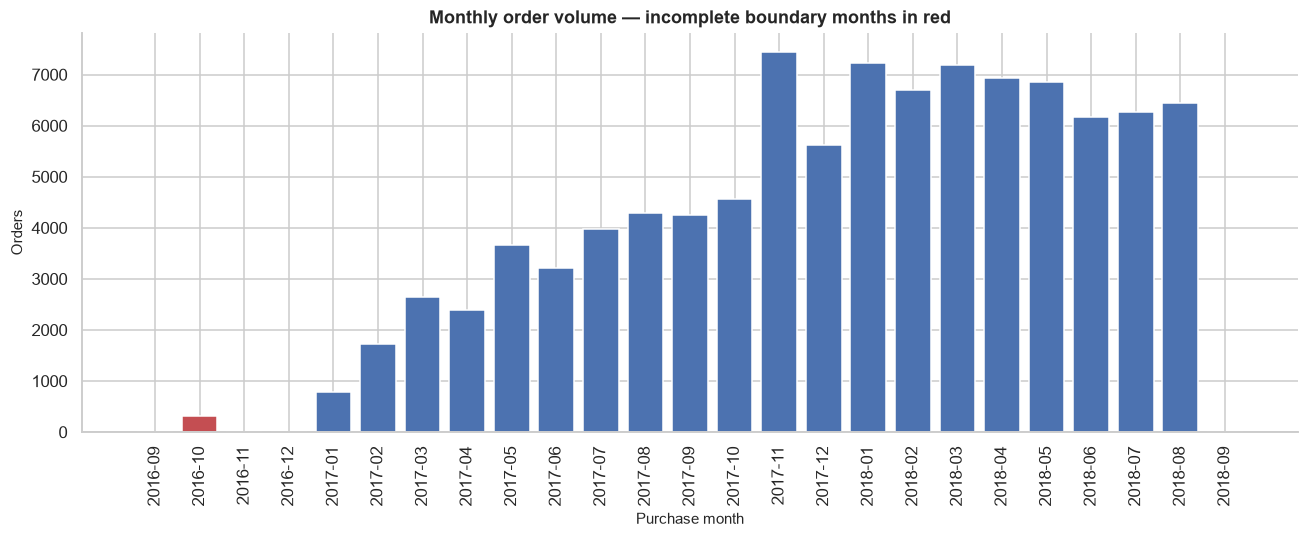

In [27]:
# Coverage figure: the shape of monthly volume, with incomplete months flagged.
# Its purpose is to show the ramp-up and the truncated tail against the stable
# operating core - not to tell a business story about growth.
colours = np.where(monthly_volume["Complete"], "#4C72B0", "#C44E52")

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(monthly_volume["Month"].astype(str), monthly_volume["Orders"], color=colours)
ax.set_title("Monthly order volume — incomplete boundary months in red")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Orders")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Decision

The analytical observation window runs from the first analytical purchase in **September 2016** to the last analytical purchase in **early September 2018**. The RFM snapshot is anchored to that end point.

Temporal analyses use the appropriate complete-period window rather than treating incomplete boundary periods as comparable full months.


## S9. Distribution Profiling: Numerical Variables

Profile numerical variables using **histograms, boxplots and ECDFs** plus compact shape summaries. The goal is to identify concentration, skew, tails and unusual values before choosing statistics/tests.


###  S9.1 Numerical Shape Screening

In [28]:
def shape_signals(series, dataset, name):
    """Shape facts a summary table does not surface: degeneracy and zero-mass."""
    data = series.dropna()
    fisher_skew = stats.skew(data, bias=False)

    return {
        "Dataset": dataset,
        "Variable": name,
        "N": len(data),
        "Distinct": data.nunique(),
        "% zeros": round((data == 0).mean() * 100, 1),
        "% at modal value": round(data.value_counts(normalize=True).iloc[0] * 100, 1),
        # What percentage of observations are concentrated at the single most common value?
        "Mean": data.mean(),
        "Median": data.median(),
        "Mean - Median": data.mean() - data.median(),
        "Skew": fisher_skew
    }

In [29]:
# There are 823 customers who are repeat buyers but have a customer lifespan of 0 days.
# This means they made multiple purchases on the same day
((rfm['is_repeat_buyer'] == True) & (rfm['customer_lifespan_days'] == 0)).sum()

np.int64(823)

In [30]:
# Repeat buyers only, reused for the lifespan profile and the independence note.
# is_repeat_buyer has no nulls (S5), so casting to a plain boolean mask is safe.
repeat_buyers = rfm[rfm["is_repeat_buyer"].astype(bool)]

# Every numerical variable named in the specification, in one place. The six
# type-specific anomaly rates are included; the raw *_count numerators are not,
# because a rate already describes their distribution.
profile_targets = [
    ("customer_rfm_features", rfm["recency_days"], "recency_days"),
    ("customer_rfm_features", rfm["frequency"], "frequency"),
    ("customer_rfm_features", rfm["monetary"], "monetary"),
    ("customer_rfm_features", rfm["avg_order_value"], "avg_order_value"),
    ("customer_rfm_features", repeat_buyers["customer_lifespan_days"], "customer_lifespan_days (repeat)"),
    ("seller_features", sellers["total_orders"], "total_orders"),
    ("seller_features", sellers["total_items"], "total_items"),
    ("seller_features", sellers["total_revenue"], "total_revenue"),
    ("seller_features", sellers["avg_order_value"], "avg_order_value"),
    ("seller_features", sellers["avg_freight_to_price_ratio"], "avg_freight_to_price_ratio"),
    ("seller_features", sellers["delivered_order_count"], "delivered_order_count"),
    ("seller_features", sellers["order_level_anomaly_rate"], "order_level_anomaly_rate"),
    ("seller_features", sellers["item_level_anomaly_rate"], "item_level_anomaly_rate"),
    ("seller_features", sellers["late_delivery_rate"], "late_delivery_rate"),
    ("seller_features", sellers["delivered_missing_approval_orders"], "delivered_missing_approval_orders"),
    ("seller_features", sellers["delivered_missing_multiple_dates_orders"], "delivered_missing_multiple_dates_orders"),
    ("seller_features", sellers["carrier_before_approval_orders"], "carrier_before_approval_orders"),
    ("seller_features", sellers["delivery_before_carrier_orders"], "delivery_before_carrier_orders"),
    ("seller_features", sellers["canceled_with_delivery_date_orders"], "canceled_with_delivery_date_orders"),
    ("seller_features", sellers["delivered_missing_final_date_orders"], "delivered_missing_final_date_orders"),
    ("seller_features", sellers["delivered_missing_carrier_anomaly_orders"], "delivered_missing_carrier_anomaly_orders"),
    ("order_delivery_features", delivery["approval_to_carrier_hours"], "approval_to_carrier_hours"),
    ("order_delivery_features", delivery["carrier_to_customer_days"], "carrier_to_customer_days"),
    ("order_delivery_features", delivery["delivery_estimate_error_days"], "delivery_estimate_error_days"),
    ("order_delivery_features", delivery["order_total_revenue"], "order_total_revenue"),
    ("order_experience_features", experience["review_score"], "review_score (ordinal)"),
]

shape_table = pd.DataFrame(
    [shape_signals(series, dataset, name) for dataset, series, name in profile_targets]
)

shape_table

,Dataset,Variable,N,Distinct,% zeros,% at modal value,Mean,Median,Mean - Median,Skew
0,customer_rfm_features,recency_days,94989,613,0.0000,1.2000,243.3628,224.0000,19.3628,0.4478
1,customer_rfm_features,frequency,94989,9,0.0000,97.0000,1.0339,1.0000,0.0339,11.5098
2,customer_rfm_features,monetary,94989,31654,0.0000,0.3000,165.6788,107.9000,57.7788,9.1067
3,customer_rfm_features,avg_order_value,94989,31816,0.0000,0.3000,160.7393,105.7400,54.9993,9.3055
4,customer_rfm_features,customer_lifespan_days (repeat),2887,422,28.5000,28.5000,87.8240,34.0000,53.8240,1.5530
5,seller_features,total_orders,3095,251,0.0000,18.4000,32.3134,6.0000,26.3134,9.6412
6,seller_features,total_items,3095,257,0.0000,16.4000,36.3974,8.0000,28.3974,9.7926
7,seller_features,total_revenue,3095,2766,0.0000,0.3000,"4,391.4842",821.4800,"3,570.0042",9.0481
8,seller_features,avg_order_value,3095,2615,0.0000,0.4000,194.6538,105.8700,88.7838,8.5577
9,seller_features,avg_freight_to_price_ratio,3095,2435,0.0000,0.2000,0.3211,0.2515,0.0696,3.1073


In [31]:
# The order-grain datasets treat each order as an observation, but a minority of
# customers placed more than one order, so those orders are not fully independent
# of each other. This quantifies that minority - the open item flagged in S6.
independence_note = pd.DataFrame(
    [
        ["Repeat buyers (share of customers)",
         f"{rfm['is_repeat_buyer'].mean() * 100:.1f}%"],
        ["Orders placed by repeat buyers (share of orders)",
         f"{repeat_buyers['frequency'].sum() / rfm['frequency'].sum() * 100:.1f}%"],
    ],
    columns=["Measure", "Value"],
)

independence_note

,Measure,Value
0,Repeat buyers (share of customers),3.0%
1,Orders placed by repeat buyers (share of orders),6.2%


Only 3.0% of customers placed more than one realised order, accounting for 6.2% of all completed orders. The overwhelming majority of observations therefore come from one-order customers, making any dependence introduced by repeat purchasers limited in practice.

## S9.2 Distribution Visualization
### Distribution gallery

Each variable below gets three views: a histogram (with median in red and mean in green) to show
where the mass sits, a boxplot to show the spread and the extremes, and an ECDF to show how the
values accumulate.The mean is strongly influenced by the upper tail, so the median is preferred as the measure of typical customer spend.

In [32]:
# Positive, heavily right-skewed variables are shown on a log x-axis so the bulk
# and the tail are both readable. This changes the axis only - no transformed
# column is ever stored.

LOG_SCALE_VARS = {"monetary", "total_orders", "total_items", "avg_order_value", "avg_freight_to_price_ratio", "order_total_revenue", "total_revenue"}

def profile_continuous(series, name, log_x=False):
    """Histogram, boxplot, and ECDF for one continuous variable, in one figure."""
    data = series.dropna()
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))

    if log_x:
        bins = np.logspace(np.log10(data[data > 0].min()), np.log10(data.max()), 50)
    else:
        bins = 50

    axes[0].hist(data, bins=bins, color="#4C72B0")
    axes[0].axvline(data.median(), color="#C44E52", lw=1.5, label="median")
    axes[0].axvline(data.mean(), color="#55A868", lw=1.5, ls="--", label="mean")
    axes[0].set_title(f"{name} — histogram")
    axes[0].legend(fontsize=8)

    axes[1].boxplot(data, orientation="horizontal", widths=0.6)
    axes[1].set_title(f"{name} — boxplot")

    x = np.sort(data.to_numpy())
    y = np.arange(1, len(x) + 1) / len(x)
    axes[2].plot(x, y, color="#4C72B0")
    axes[2].set_title(f"{name} — ECDF")

    if log_x:
        for ax in axes:
            ax.set_xscale("log")

    plt.tight_layout()
    plt.show()



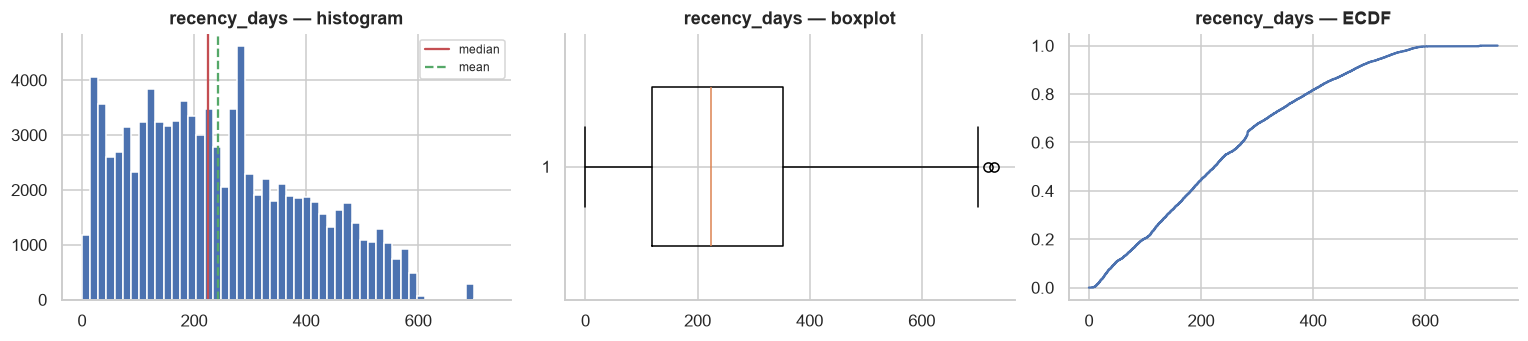

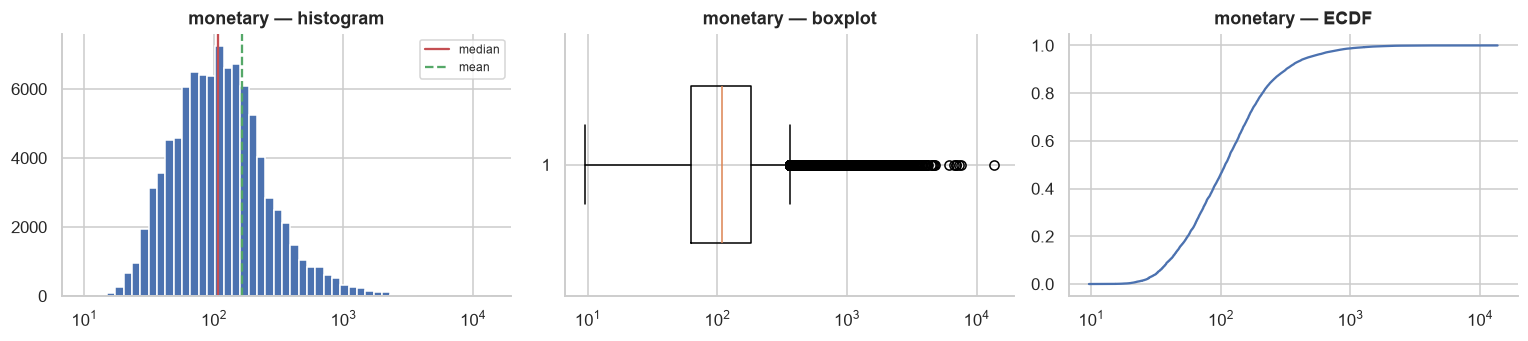

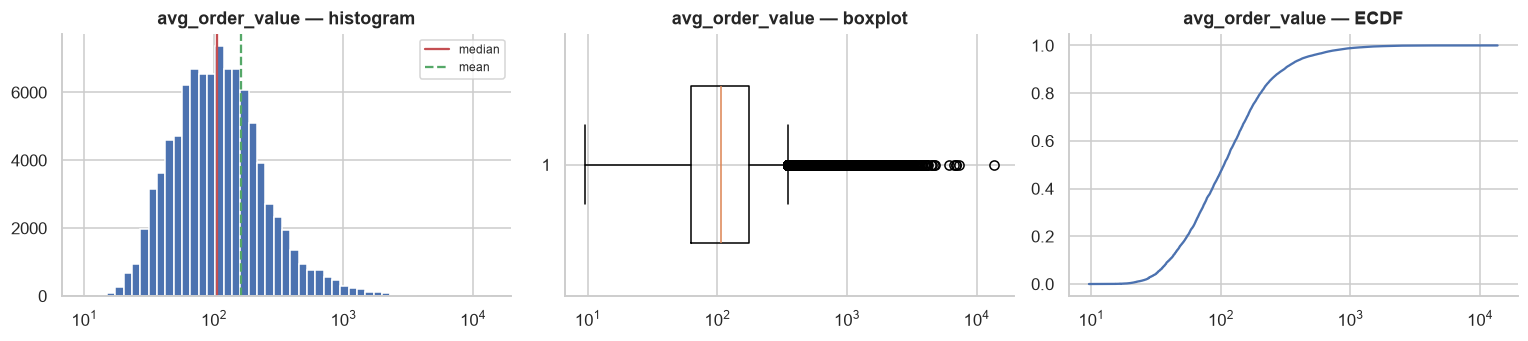

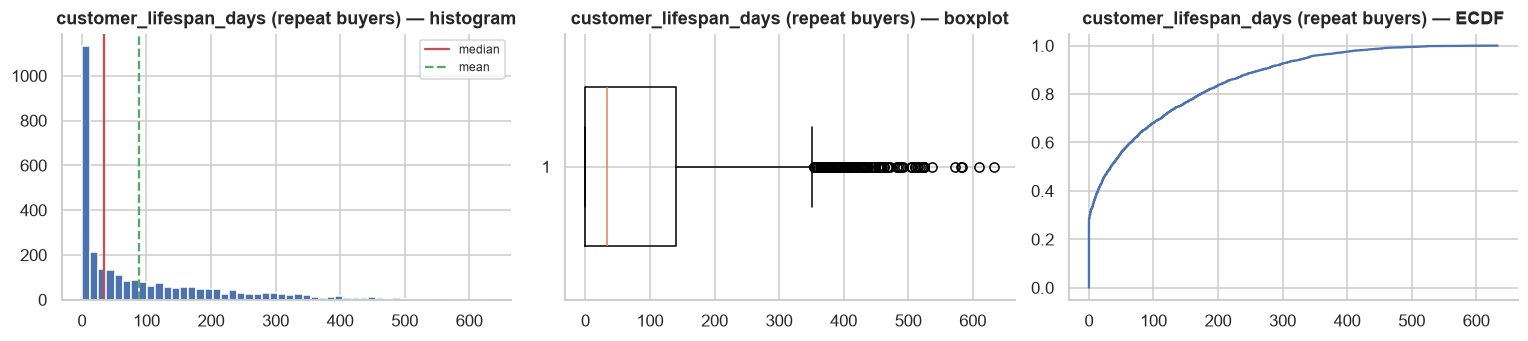

In [33]:
# Customer value (RFM). Watch frequency: near-total mass on a single value.
for name, series in [
    ("recency_days", rfm["recency_days"]),
    ("monetary", rfm["monetary"]),
    ("avg_order_value", rfm["avg_order_value"]),
    ("customer_lifespan_days (repeat buyers)", repeat_buyers["customer_lifespan_days"]),
]:
    profile_continuous(series, name, log_x=name.split()[0] in LOG_SCALE_VARS)

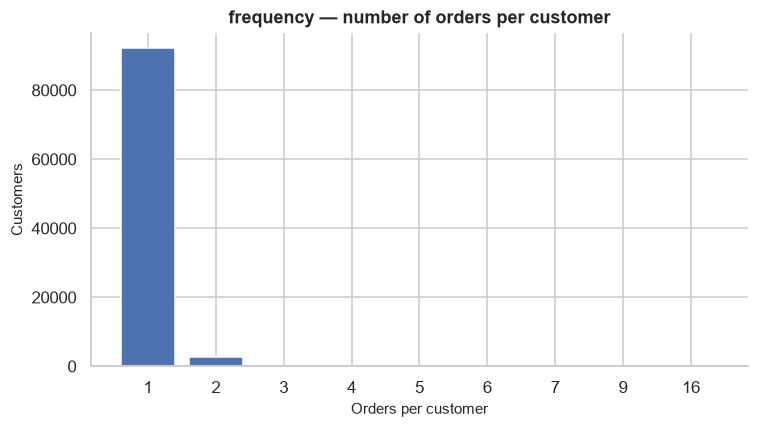

In [34]:
frequency_counts = rfm["frequency"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    frequency_counts.index.astype(str),
    frequency_counts.values
)

ax.set_title("frequency — number of orders per customer")
ax.set_xlabel("Orders per customer")
ax.set_ylabel("Customers")

plt.tight_layout()
plt.show()

### 1. recency_days
**Histogram** — Mass spreads across the first few hundred days with a mild right tail. Mean and median sit close together.
**Boxplot** — The middle 50% of customers occupy a moderate range; a small right-side tail extends to customers who purchased long ago.
**ECDF** — The curve rises steadily rather than in one sharp step, meaning values are spread across the range rather than concentrated at a point.

**Shape summary:** continuous, mildly right-skewed, no zero- or single-value concentration.

### 2. frequency
97% of customers placed exactly one order, while only a small minority purchased repeatedly. frequency is therefore highly concentrated and is better represented by the binary is_repeat_buyer variable for repeat-purchase analysis.

### 3. monetary
**Histogram (log scale)** — Strong right skew: most customers spend a modest amount, with a
long tail of high-value orders.
**Boxplot** — Narrow box, many points beyond the upper whisker.
**ECDF** — Rises quickly at low values, then flattens into a long, thin tail.

**Shape summary:** continuous, strongly right-skewed, mean sits well above median.

### 4. avg_order_value
Same shape pattern as `monetary`: strong right skew, long upper tail, mean above median.

### 5. customer_lifespan_days (repeat buyers only)

**Histogram** — A substantial share of repeat buyers have a lifespan of 0 days, followed by a long right tail representing customers who returned much later.
**Boxplot** — Wide spread with many upper-end observations beyond the upper whisker.
**ECDF** — A noticeable jump at 0 days followed by a gradual rise across longer lifespans.

**Shape summary:** right-skewed with a substantial point mass at zero. The profile is restricted to repeat buyers because one-time customers have no meaningful customer lifespan.

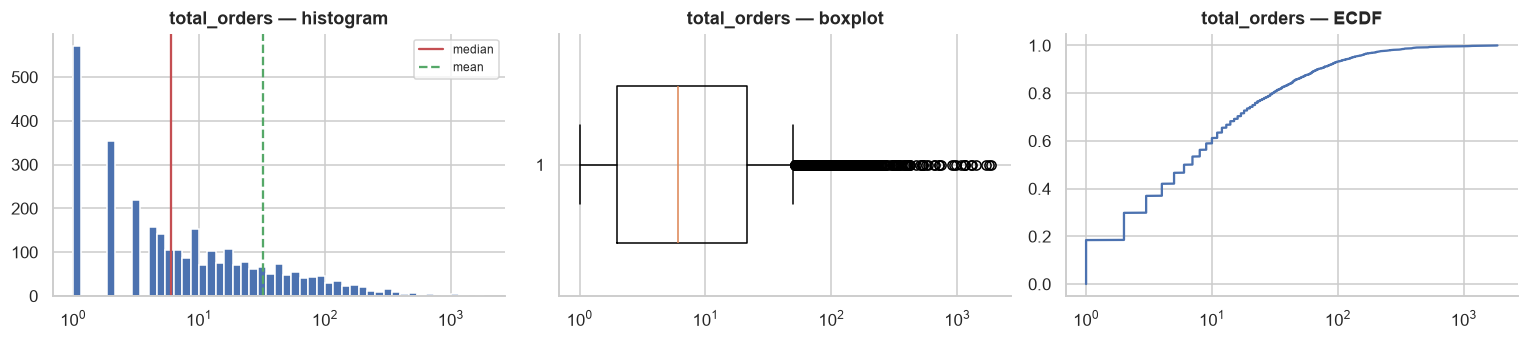

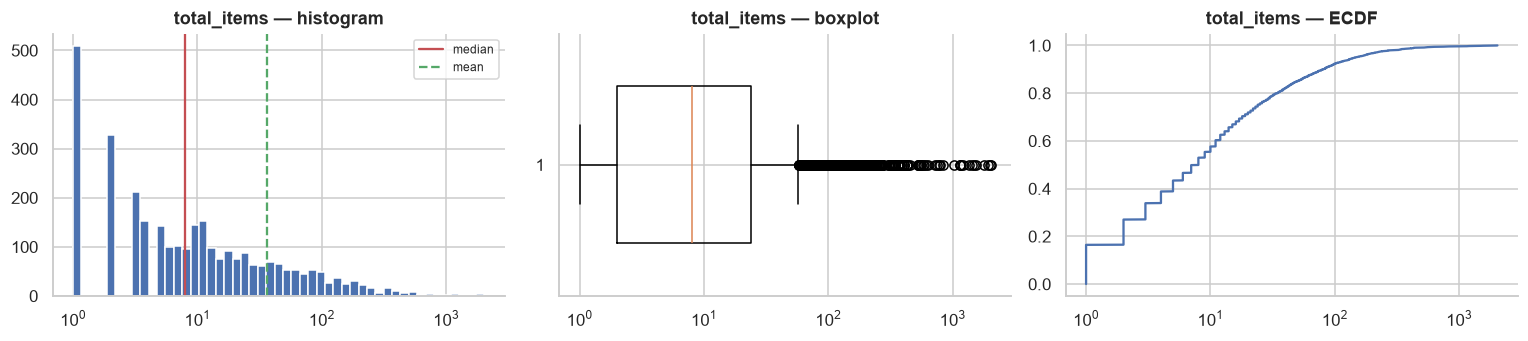

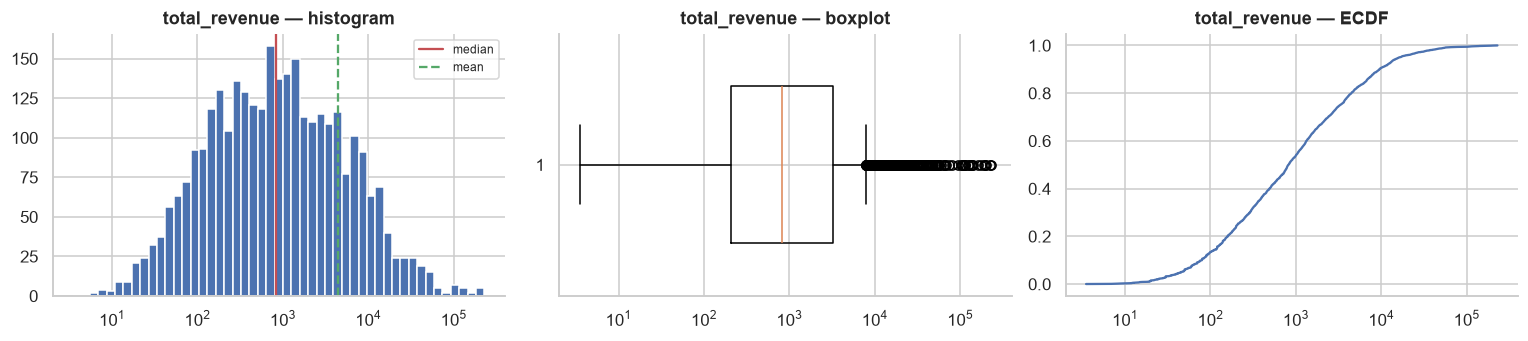

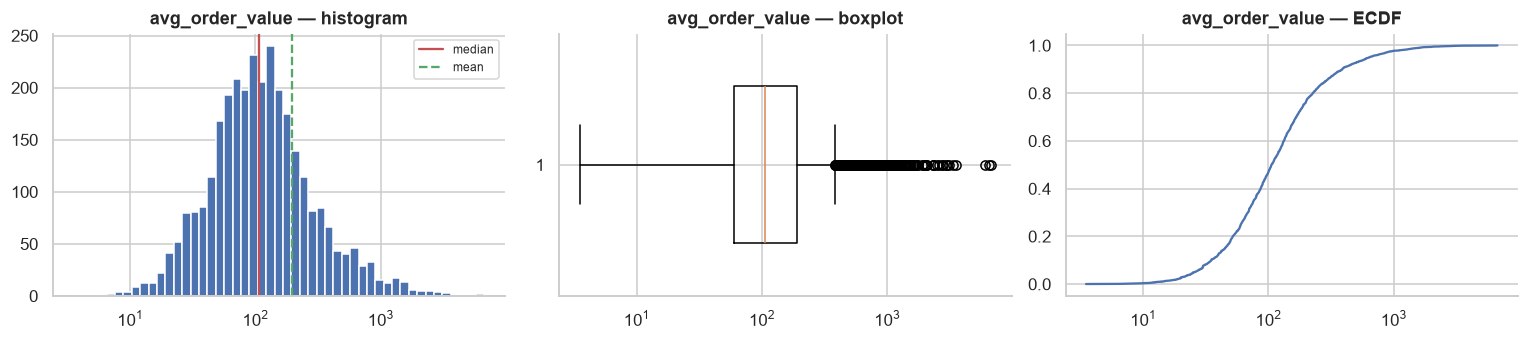

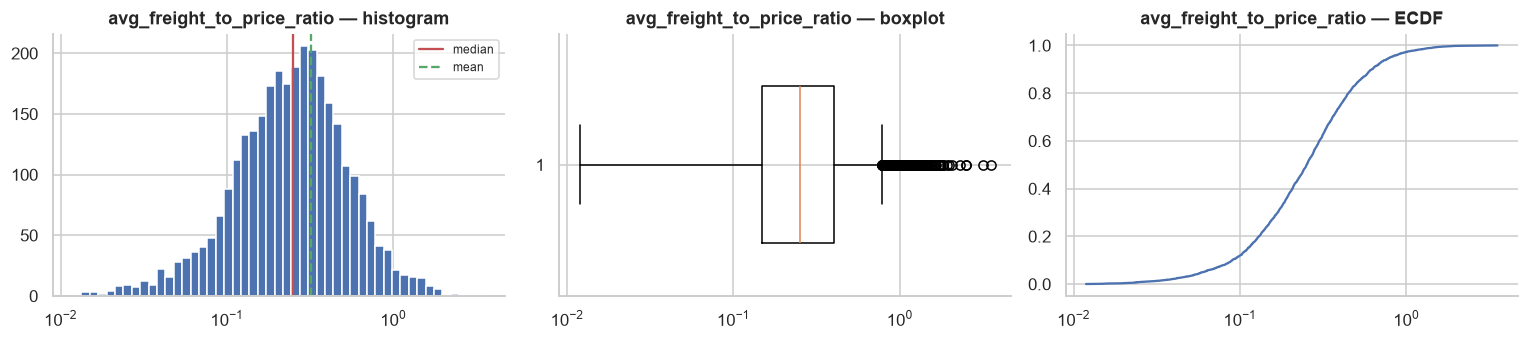

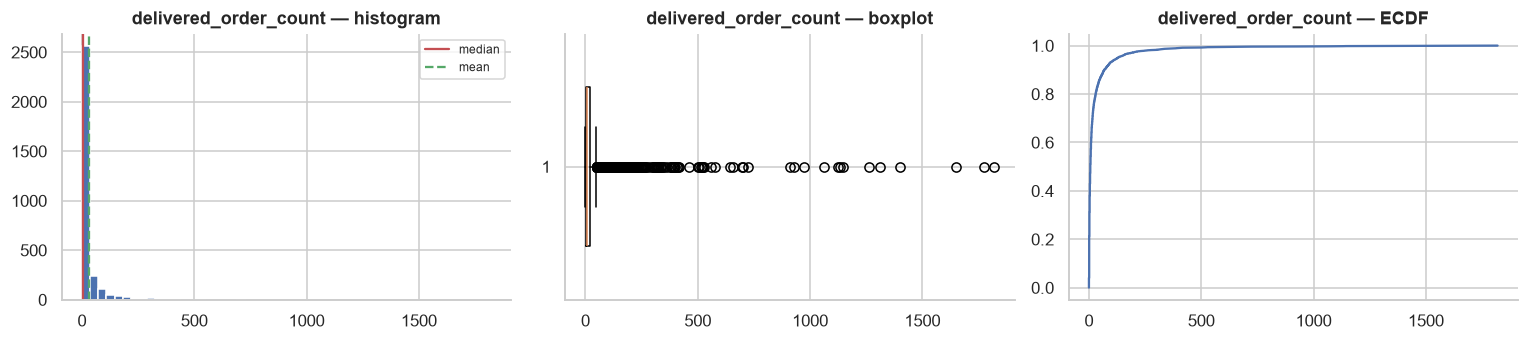

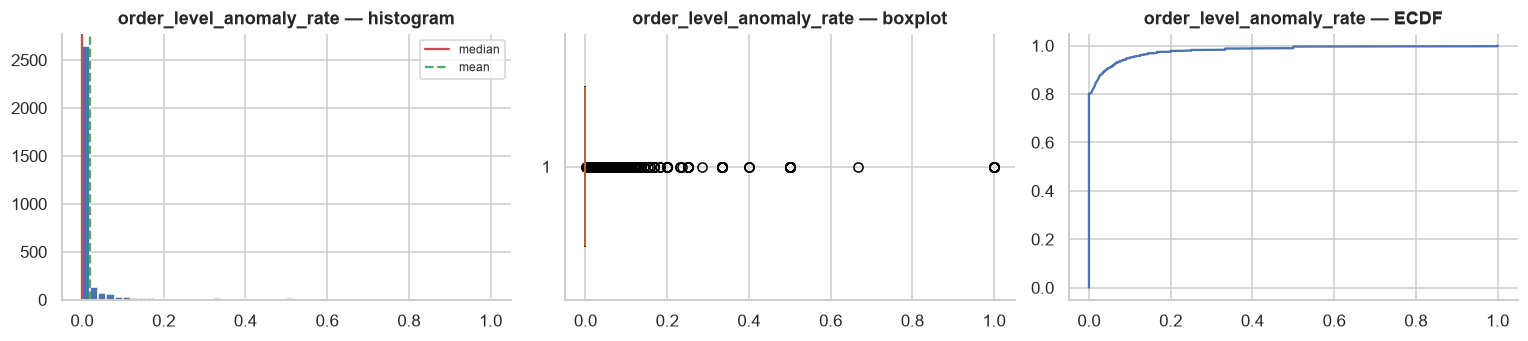

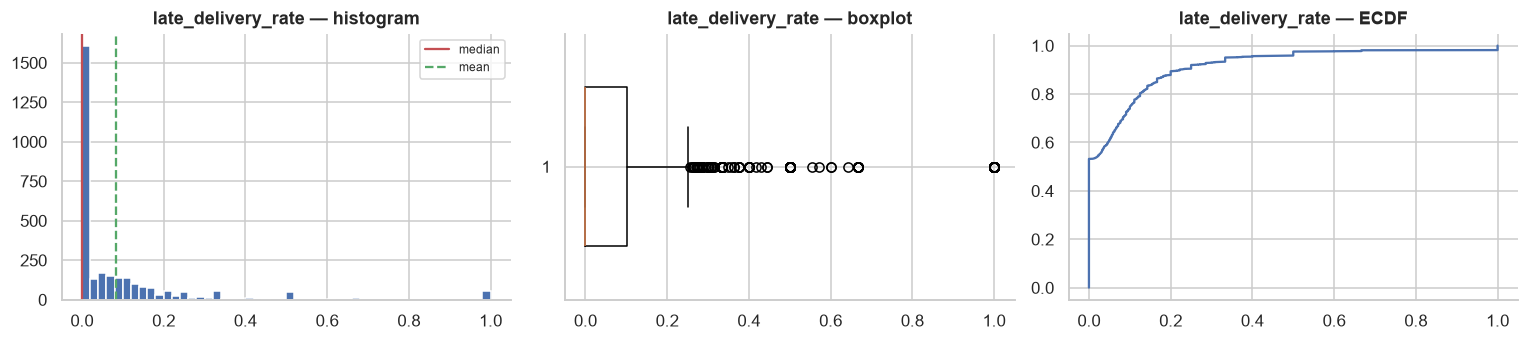

In [35]:
# Seller volume and the two headline risk rates. The rates carry most of their
# mass at zero - most sellers have no anomalies and no late deliveries.
for name in ["total_orders", "total_items", "total_revenue", "avg_order_value", "avg_freight_to_price_ratio", "delivered_order_count","order_level_anomaly_rate", "late_delivery_rate"]:
    profile_continuous(sellers[name], name, log_x=name in LOG_SCALE_VARS)

### 1. total_orders
**Histogram** - Most sellers have completed very few orders. Only a handful of sellers process hundreds or even thousands of orders. Mean lies much farther right than the median because a few very large sellers pull the average upward.
**Boxplot** - The median seller has very few orders.
Many sellers appear as outliers, but these are expected high-volume businesses rather than data errors.
**ECDF**- Around 60% of sellers have roughly fewer than 10 orders. More than 90% have fewer than ~100 orders. Only a tiny fraction are very large sellers.
**Interpretation** - Seller order volume is extremely right-skewed. Most sellers are very small, while a small number dominate marketplace activity.

### 2. total_items
**Histogram** - Very similar shape to total_orders. Most sellers sell relatively few items. A few sellers contribute extremely large item volumes.
**Boxplot** - Large number of upper-end outliers. Again, these represent genuine high-volume sellers.
**ECDF** - Majority of sellers have relatively small inventories sold. Only a small percentage account for most items sold.
**Interpretation** - Item volume follows the same marketplace concentration seen in order volume, confirming that seller activity is highly unequal.

### 3. total revenue
**Histogram** — Most sellers generate relatively modest revenue, with a long upper tail from a small number of high-volume sellers.
**Boxplot** — The median is far below the mean, with numerous high-end observations beyond the upper whisker.
**ECDF** — Most sellers accumulate at the lower end of the revenue range, while a small group extends far into the upper tail.

**Shape summary:** strongly right-skewed. Seller revenue is highly concentrated, with a small number of sellers accounting for disproportionately high revenue.

### 4. avg_order_value
**Histogram** — Most sellers have relatively low average order values, with a long upper tail.
**Boxplot** — The mean is pulled above the median by high-AOV sellers and several upper-end observations.
**ECDF** — Most sellers fall below the upper tail, while a small group has substantially higher average order values.

**Shape summary:** right-skewed, with the median providing a better representation of the typical seller's AOV.

### 5. avg_freight_to_price_ratio
**Histogram** — Most sellers cluster toward lower freight-to-price ratios, with a right tail of sellers where freight represents a larger share of item price.
**Boxplot** — The mean lies above the median, indicating an upper tail of relatively high freight ratios.
**ECDF** — Most sellers are concentrated toward the lower end, followed by a gradual upper tail.

**Shape summary:** right-skewed bounded ratio. The variable has substantial variation across sellers but is not treated as a monetary amount.

### 6. delivered_order_count
**Histogram** - Huge spike near one. Most sellers have delivered only a small number of orders. Long tail extends to sellers with over 1000 deliveries.
**Boxplot** - Median is very low. Numerous upper outliers correspond to established sellers.
**ECDF** - Around 90% of sellers have relatively few completed deliveries. Very few sellers handle large delivery volumes.
**Interpretation** - Delivered order counts are heavily concentrated among a small number of sellers. This is exactly why percentage-based seller metrics become unstable for low-volume sellers.

### 7. order_level_anomaly_rate
**Shape summary:** The distribution is strongly zero-inflated: **80.1% of sellers have a 0% anomaly rate**, while a small minority have positive rates extending into the upper tail.
This makes the rate unsuitable for treating all sellers as equally informative; low-volume sellers can show extreme rates from very few orders.

 ### 8. late_delivery_rate
**Histogram** - Most sellers have zero or only a few late deliveries. Only a handful accumulate large numbers of late deliveries.
**Boxplot** - Median is essentially zero. Around 55% sellers have 0% delivery rate. Long upper tail exists.
**ECDF** - Large majority of sellers never experience many late deliveries.
**Interpretation** - Late delivery is uncommon for most sellers: over half record a rate of exactly zero, with a thin upper tail. The rate normalises for seller volume, but low-volume sellers can still have unstable rates; seller volume reliability is assessed separately in S15.

In [36]:
# Compute type-specific rates on the fly (counts stored, rates derived)
anomaly_types = {
    "shipping_anomaly_rate":              sellers["item_level_anomaly_rate"],
    "missing_approval_rate":              sellers["delivered_missing_approval_orders"] / sellers["total_orders"],
    "missing_multiple_dates_rate":        sellers["delivered_missing_multiple_dates_orders"] / sellers["total_orders"],
    "carrier_before_approval_rate":       sellers["carrier_before_approval_orders"] / sellers["total_orders"],
    "delivery_before_carrier_rate":       sellers["delivery_before_carrier_orders"] / sellers["total_orders"],
    "canceled_with_delivery_date_rate":   sellers["canceled_with_delivery_date_orders"] / sellers["total_orders"],
    "missing_final_date_rate":            sellers["delivered_missing_final_date_orders"] / sellers["total_orders"],
    "missing_carrier_anomaly_rate":        sellers["delivered_missing_carrier_anomaly_orders"] / sellers["total_orders"],
}

anomaly_profile = []

for k,v in anomaly_types.items():
    data = v.dropna()
    positive = (v>0).sum()
    zero = (v==0).sum()

    anomaly_profile.append({
    "Anomaly": k,
    "Positive - rate sellers": positive,
    "Zero - rate sellers": zero,
    "% positive": round(positive/ len(data) * 100, 2)
    })

anomaly_profile = pd.DataFrame(anomaly_profile).sort_values(by="% positive").reset_index(drop=True)

anomaly_profile

,Anomaly,Positive - rate sellers,Zero - rate sellers,% positive
0,shipping_anomaly_rate,1,3094,0.0300
1,missing_multiple_dates_rate,1,3094,0.0300
2,missing_carrier_anomaly_rate,2,3093,0.0600
3,canceled_with_delivery_date_rate,5,3090,0.1600
4,missing_final_date_rate,6,3089,0.1900
5,missing_approval_rate,10,3085,0.3200
6,delivery_before_carrier_rate,40,3055,1.2900
7,carrier_before_approval_rate,584,2511,18.8700


### 9-16. Seller anomaly-type rates

These anomaly types are highly zero-inflated. Most have positive rates in only a handful of sellers, while carrier_before_approval_rate is substantially more prevalent.

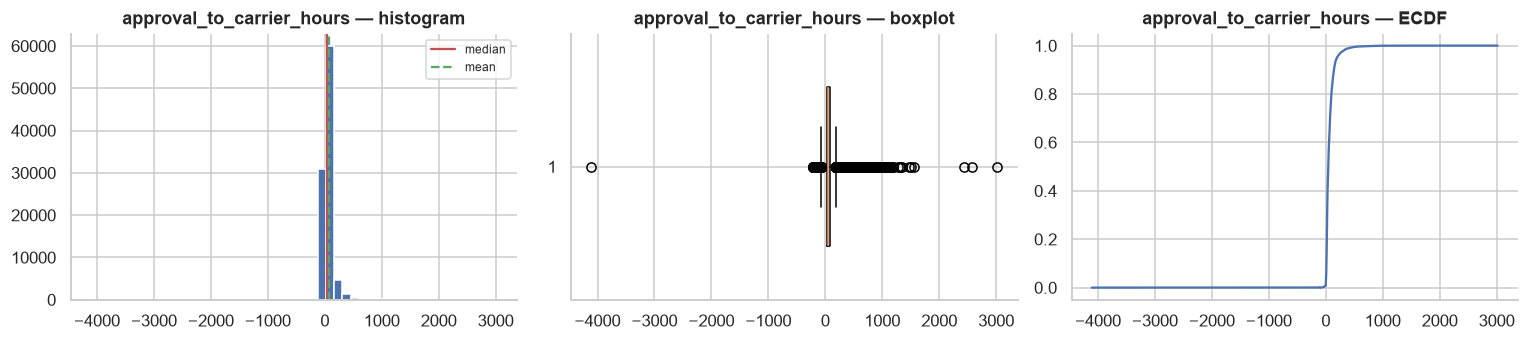

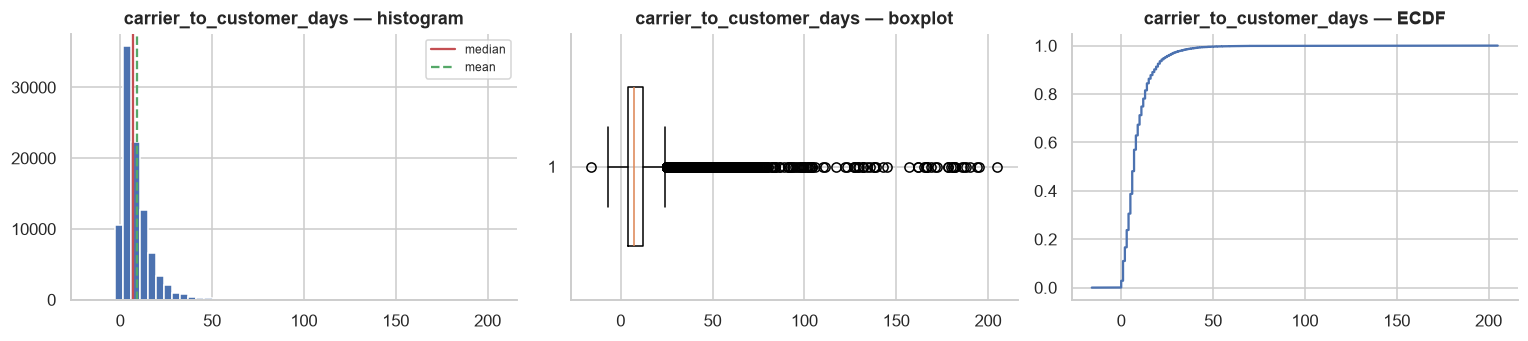

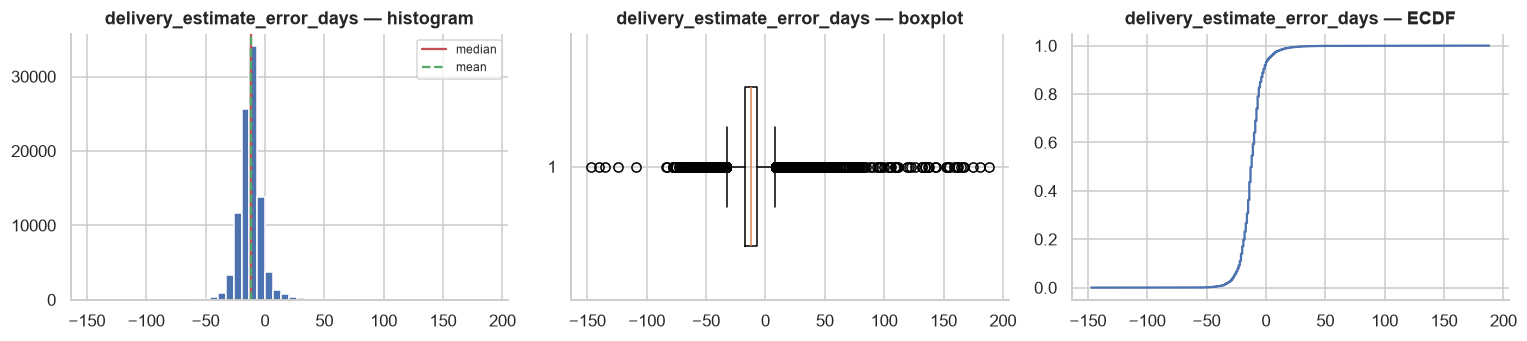

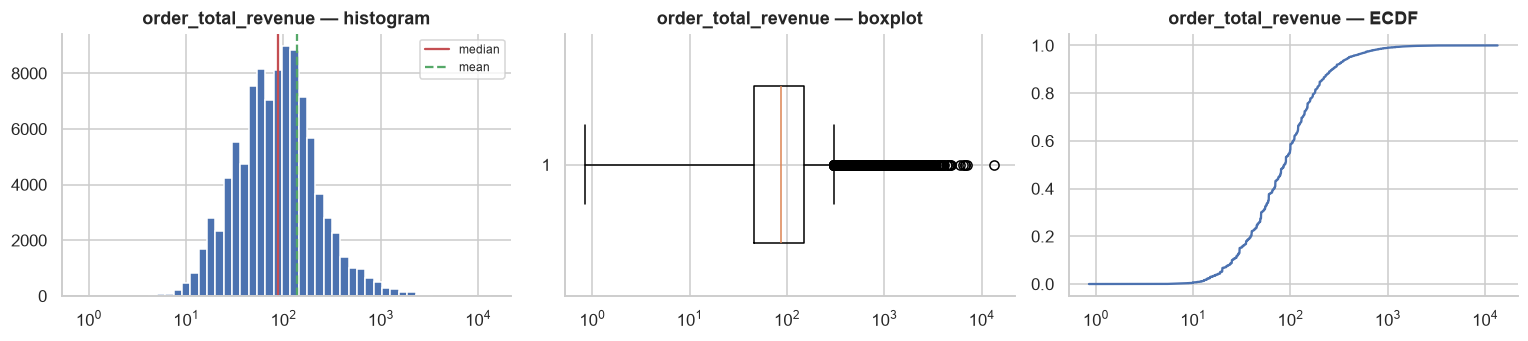

In [37]:
# Delivery stage durations and the size of the delivery miss. Durations can be
# negative for the timestamp-ordering anomalies, so they are shown on a linear
# scale; error days is signed by design (negative = early).
for name in ["approval_to_carrier_hours", "carrier_to_customer_days", "delivery_estimate_error_days", "order_total_revenue"]:
    profile_continuous(delivery[name], name, log_x=name in LOG_SCALE_VARS)

### 1. approval_to_carrier_hours
**Histogram** — Most orders are picked up within a short window after approval; a long right tail extends to orders that took much longer. A small number of negative values are present.
**Boxplot** — Median is around 43 hours, with most observations concentrated in the lower range and a long upper tail.
**ECDF** — Rises almost vertically near zero, then flattens — most mass sits in a narrow interval.

**Shape summary:** strongly right-skewed, mean exceeds median. The negative values were already
traced to specific timestamp-ordering anomalies during warehouse cleaning.

### 2. carrier_to_customer_days
**Histogram** — Most deliveries fall within a common range, with a small number taking substantially longer.
**Boxplot** — Median in the single-digit-to-low-double-digit range; right-side outliers extend well beyond it.
**ECDF** — Reaches most of its mass quickly, then a long, thin tail.

**Shape summary:** right-skewed, mean exceeds median. Long-duration orders are not treated as
errors here — later part investigation

### 3. delivery_estimate_error_days
Negative = delivered early. Positive = delivered late. Zero = exactly on the estimated day.

**Histogram** — Centred near zero with mass on both sides, unlike the two duration variables above.
**Boxplot** — Most values cluster near zero; both early and late extremes are present.
**ECDF** — Steep rise around zero — most orders land close to the estimate, with thinner tails on both sides.

**Shape summary:** approximately symmetric-to-mildly-skewed around a slightly negative centre, unlike the strictly positive durations above. This shape is what allows early/on-time/late comparisons in later analysis — no conclusion about delivery performance is drawn here.

### 4. order_total_revenue

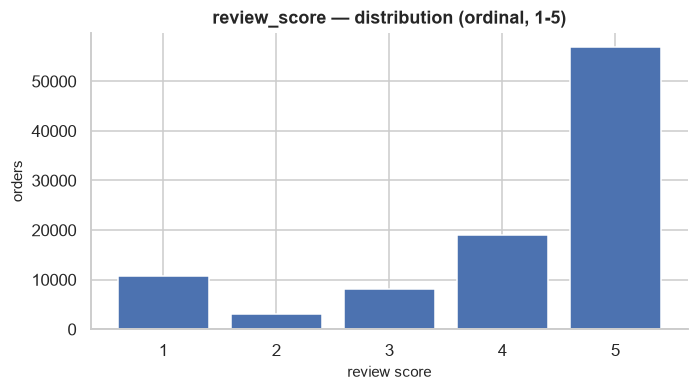

In [38]:
# review_score is ordinal (S7), so its honest view is a count of each rating,
# not a histogram that would imply equal spacing between stars.
review = experience["review_score"].dropna()
counts = review.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(counts.index, counts.values, color="#4C72B0")
ax.set_title("review_score — distribution (ordinal, 1-5)")
ax.set_xlabel("review score")
ax.set_ylabel("orders")
plt.show()


`order_total_revenue` is shared across the two order-grain analytical datasets and is profiled once because its distribution is identical.

### Decision

These are shape observations used to guide Notebook 02.

- `frequency` is near-degenerate: about **97% of customers purchased once**, so repeat behaviour is better represented by `is_repeat_buyer` than by treating frequency as a continuous outcome.
- Delivery durations and monetary measures are strongly/right-skewed; median-led reporting is therefore preferred.
- Negative or extreme duration values are retained and handled through the documented anomaly/outlier rules.


## S10. Distribution Profiling: Categorical Variables

Profile category frequencies and group sizes. The key purpose is to identify **rare groups that cannot support reliable comparisons** in Notebook 02.

**Special handling, consistent with earlier sections:**

- **Null categories are excluded, not imputed.** Some customers have no first-purchase category (their first order had no line items). S5 fixed the rule: category analysis runs on customers who have a category, and the missing ones are counted and set aside, never filled in.
- **The <30-unit grouping rule from S2 is applied** to the product-category variable, collapsing categories with fewer than 30 units into an `other` bucket. This is the frozen grouping, and its effect on the group-size problem is measured here rather than assumed to fix it.

In [39]:
# Every categorical variable named in the specification, with its dataset and grain. 
# Customer state is taken from the customer-grain RFM table so each customer is counted once, not once per order.

categorical_targets = [
    ("customer_rfm_features", rfm["customer_state"], "customer_state"),
    ("customer_rfm_features", rfm["first_purchase_category"], "first_purchase_category"),
    ("customer_rfm_features", rfm["is_repeat_buyer"], "is_repeat_buyer"),
    ("seller_features", sellers["seller_state"], "seller_state"),
    ("seller_features", sellers["seller_volume_tier"], "seller_volume_tier"),
    ("seller_features", sellers["seller_tenure_bucket"], "seller_tenure_bucket"),
    ("seller_features", sellers["primary_category"], "primary_category"),
    ("order_experience_features", experience["anomaly_severity_tier"], "anomaly_severity_tier"),
    ("order_experience_features", experience["lateness_bucket"], "lateness_bucket"),
    ("order_experience_features", experience["has_review"], "has_review"),
    ("order_experience_features", experience["is_negative_review"], "is_negative_review"),
    ("order_experience_features", experience["has_fulfillment_anomaly"], "has_fulfillment_anomaly"),
    ("order_delivery_features", delivery["order_status"], "order_status"),
    ("order_delivery_features", delivery["is_delivered"], "is_delivered"),
    ("order_delivery_features", delivery["customer_state"], "customer_state"),
    ("order_delivery_features", delivery["primary_seller_state"], "primary_seller_state"),
    ("order_delivery_features", delivery["primary_category"], "primary_category"),
    ("order_delivery_features", delivery["has_delivery_timestamp_anomaly"], "has_delivery_timestamp_anomaly"),
    ("order_delivery_features", delivery["is_cross_state"], "is_cross_state"),
    ("order_delivery_features", delivery["is_delivered_on_time"], "is_delivered_on_time"),
]


def category_summary(series, dataset, name):
    """Cardinality, dominance, and imbalance for one categorical variable."""
    counts = series.value_counts(dropna=True)
    total = len(series)
    non_null_total = counts.sum()

    return {
        "Dataset": dataset,
        "Variable": name,
        "Distinct": series.nunique(dropna=True),
        "Nulls": int(series.isna().sum()),
        "Null %": round(series.isna().mean() * 100, 1),
        "Dominant category": counts.index[0] if len(counts) else None,
        "Dominant %": round(counts.iloc[0] / total * 100, 1) if len(counts) else 0,
        "Smallest %": round(counts.iloc[-1] / total * 100, 2) if len(counts) else 0,
    }


cardinality_summary = pd.DataFrame(
    [category_summary(series, dataset, name) for dataset, series, name in categorical_targets]
)

cardinality_summary

,Dataset,Variable,Distinct,Nulls,Null %,Dominant category,Dominant %,Smallest %
0,customer_rfm_features,customer_state,27,0,0.0000,SP,41.8000,0.0500
1,customer_rfm_features,first_purchase_category,74,32,0.0000,cama_mesa_banho,9.3000,0.0000
2,customer_rfm_features,is_repeat_buyer,2,0,0.0000,False,97.0000,3.0400
3,seller_features,seller_state,23,0,0.0000,SP,59.7000,0.0300
4,seller_features,seller_volume_tier,3,0,0.0000,low,33.3000,33.3100
5,seller_features,seller_tenure_bucket,2,0,0.0000,established,92.1000,7.9200
6,seller_features,primary_category,70,0,0.0000,beleza_saude,9.8000,0.0300
7,order_experience_features,anomaly_severity_tier,4,0,0.0000,none,98.6000,0.0100
8,order_experience_features,lateness_bucket,5,0,0.0000,early,89.8000,1.3100
9,order_experience_features,has_review,2,0,0.0000,True,99.2000,0.7600


In [40]:
# None of them carry nulls (S5), which the Nulls column confirms.

boolean_vars = [
    ("is_repeat_buyer", rfm["is_repeat_buyer"]),
    ("is_cross_state", delivery["is_cross_state"]),
    ("has_review", experience["has_review"]),
    ("has_fulfillment_anomaly", experience["has_fulfillment_anomaly"]),
    ("is_delivered", delivery["is_delivered"]),
    ("has_delivery_timestamp_anomaly", delivery["has_delivery_timestamp_anomaly"])
]

boolean_table = pd.DataFrame(
    [
        {
            "Variable": name,
            "True %": round(series.mean() * 100, 1),
            "False %": round((1 - series.mean()) * 100, 1),
            "Nulls": int(series.isna().sum()),
        }
        for name, series in boolean_vars
    ]
)

boolean_table

,Variable,True %,False %,Nulls
0,is_repeat_buyer,3.0000,97.0000,0
1,is_cross_state,64.0000,36.0000,0
2,has_review,99.2000,0.8000,0
3,has_fulfillment_anomaly,1.4000,98.6000,0
4,is_delivered,97.8000,2.2000,0
5,has_delivery_timestamp_anomaly,1.4000,98.6000,0


### Categorical distributions

Bar charts are shown only for the mid-cardinality variables, where seeing the imbalance is more
useful than reading it. The two ordinal ones — `lateness_bucket` and `anomaly_severity_tier` —
are drawn in their natural order rather than by count, so the shape reads correctly.

In [41]:
experience['lateness_bucket'].value_counts()

lateness_bucket
early            88649
very_late         4665
not delivered     2190
slightly_late     1870
on_time           1292
Name: count, dtype: int64

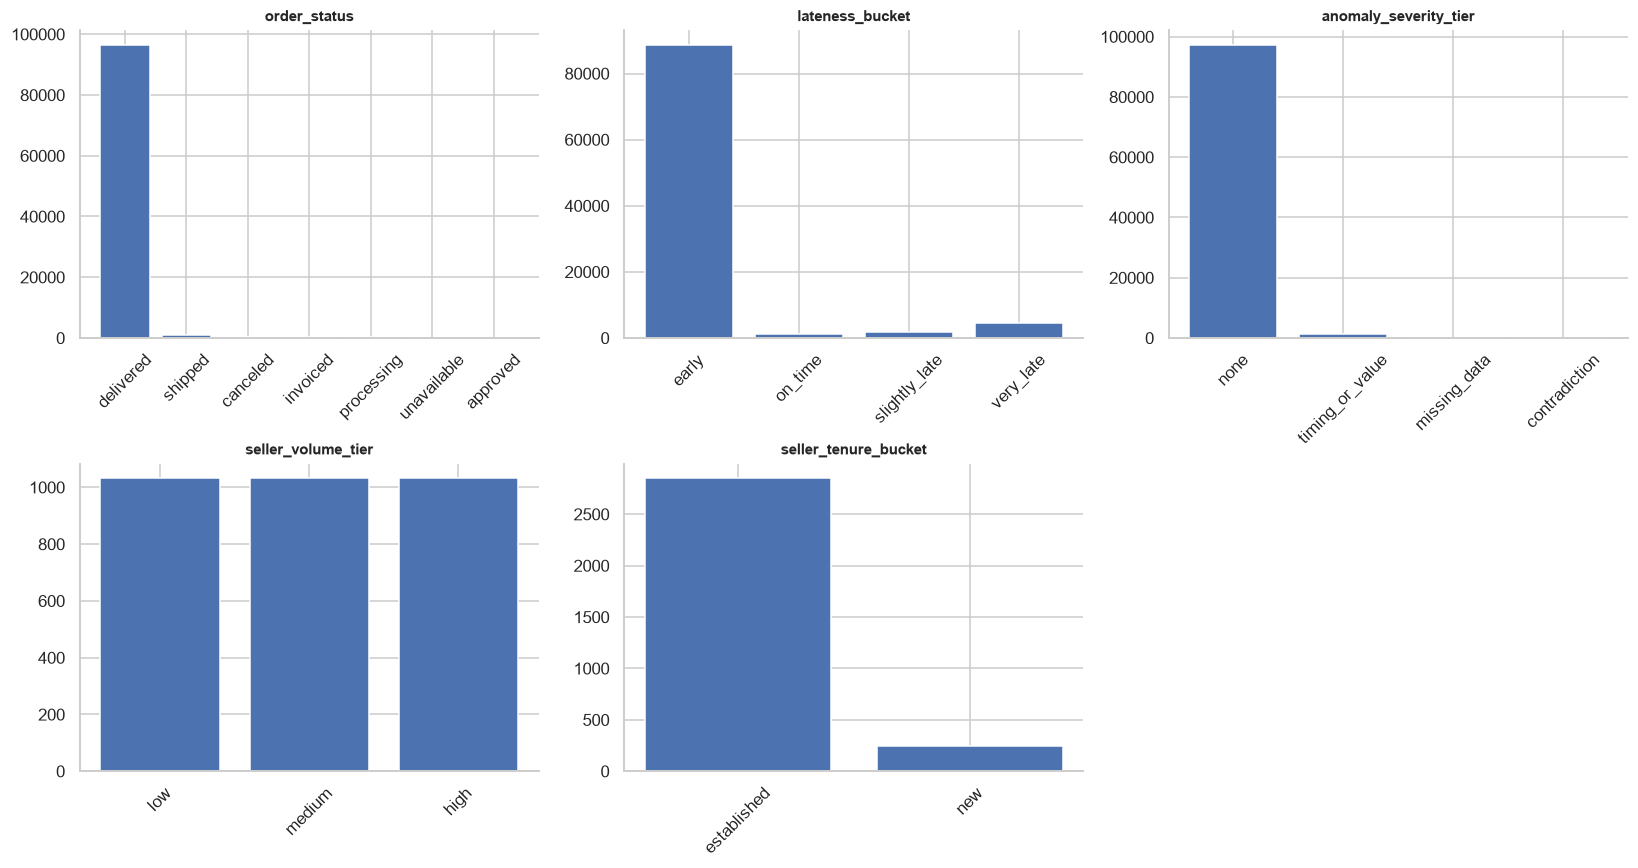

In [42]:
# Ordinal categoricals are drawn in their logical order, not by frequency, so
# the progression is readable.
CATEGORY_ORDER = {
    "lateness_bucket": ["early", "on_time", "slightly_late", "very_late", "not_delivered"]
}

chart_targets = [
    ("order_status", delivery["order_status"]),
    ("lateness_bucket", experience["lateness_bucket"]),
    ("anomaly_severity_tier", experience["anomaly_severity_tier"]),
    ("seller_volume_tier", sellers["seller_volume_tier"]),
    ("seller_tenure_bucket", sellers["seller_tenure_bucket"])
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, series) in zip(axes.ravel(), chart_targets):
    counts = series.value_counts()
    if name in CATEGORY_ORDER:
        counts = counts.reindex(CATEGORY_ORDER[name])
    ax.bar(counts.index.astype(str), counts.values, color="#4C72B0")
    ax.set_title(name, fontsize=10)
    ax.tick_params(axis="x", rotation=45)

axes.ravel()[-1].axis("off")  # only five charts
plt.tight_layout()
plt.show()

### Geographic concentration (states)

States are high-cardinality (27 values), so a Pareto view is the useful one: how much of the base
sits in the top few states. The cumulative line makes the concentration obvious at a glance.

In [43]:
def pareto(series):
    """Counts, share, and cumulative share, ordered from most to least common."""
    counts = series.value_counts()
    pct = counts / counts.sum() * 100
    return pd.DataFrame(
        {"Count": counts, "%": pct.round(2), "Cumulative %": pct.cumsum().round(2)}
    )


customer_state_pareto = pareto(rfm["customer_state"])
seller_state_pareto = pareto(sellers["seller_state"])

customer_state_pareto.head(10)

,Count,%,Cumulative %
customer_state,,,
SP,39744,41.8400,41.8400
RJ,12239,12.8800,54.7300
MG,11129,11.7200,66.4400
RS,5233,5.5100,71.9500
PR,4821,5.0800,77.0300
SC,3498,3.6800,80.7100
BA,3242,3.4100,84.1200
DF,2054,2.1600,86.2800
ES,1950,2.0500,88.3400


In [44]:
seller_state_pareto.head(10)

,Count,%,Cumulative %
seller_state,,,
SP,1849,59.7400,59.7400
PR,349,11.2800,71.0200
MG,244,7.8800,78.9000
SC,190,6.1400,85.0400
RJ,171,5.5300,90.5700
RS,129,4.1700,94.7300
GO,40,1.2900,96.0300
DF,30,0.9700,97.0000
ES,23,0.7400,97.7400


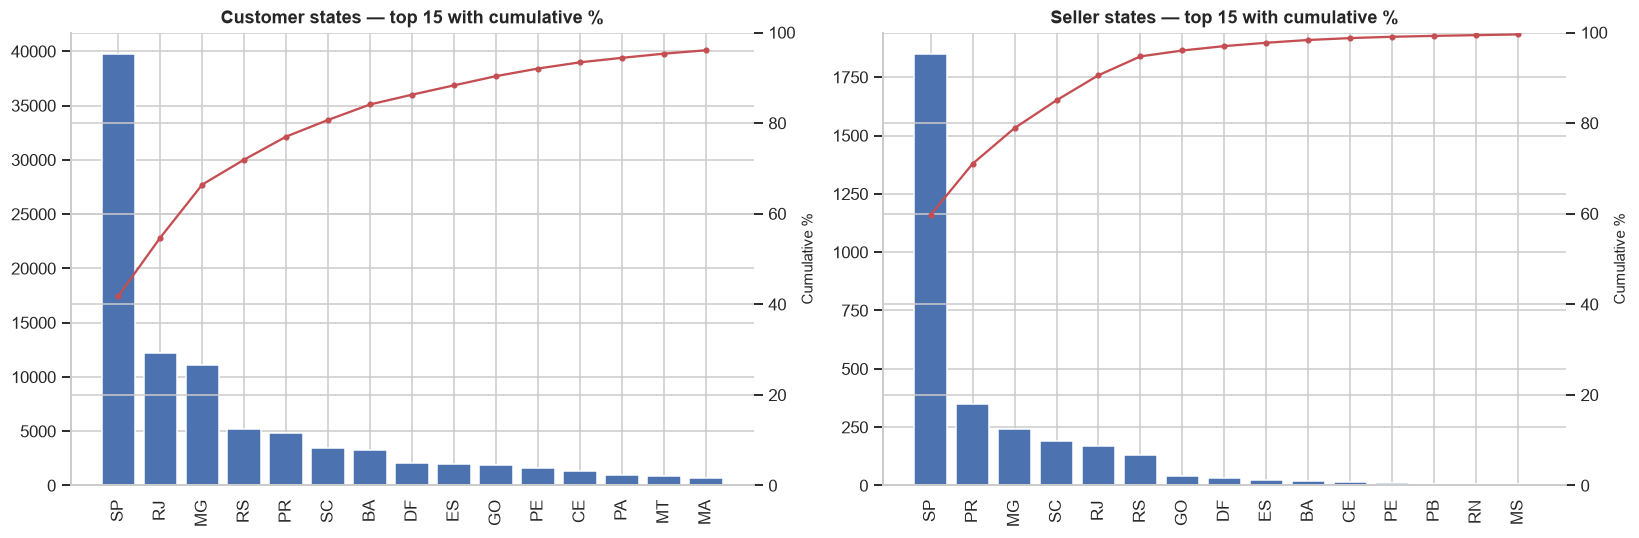

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (title, table) in zip(
    axes, [("Customer states", customer_state_pareto), ("Seller states", seller_state_pareto)],):
    top = table.head(15)
    ax.bar(top.index, top["Count"], color="#4C72B0")
    ax.set_title(f"{title} — top 15 with cumulative %")
    ax.tick_params(axis="x", rotation=90)
    twin = ax.twinx()
    twin.plot(top.index, top["Cumulative %"], color="#C44E52", marker="o", markersize=3)
    twin.set_ylabel("Cumulative %")
    twin.set_ylim(0, 100)
plt.tight_layout()
plt.show()

### Product category and the repeat-rate group-size problem

`first_purchase_category` is the highest-cardinality variable in the project and the one behind a
planned comparison — do certain first categories lead to more repeat buying (H1). This is where
the group-size check matters most, so it is worked through in three steps: the raw problem, the
frozen grouping, and what remains after grouping.

In [46]:
# Null categories are excluded, per S5, and counted so they are accounted for.
category_counts = rfm["first_purchase_category"].value_counts(dropna=True)

print(f"Distinct categories                 : {category_counts.size}")
print(f"Customers with a category            : {int(category_counts.sum()):,}")
print(f"Customers with no category (excluded) : {int(rfm['first_purchase_category'].isna().sum()):,}")

category_counts.head(15)

Distinct categories                 : 74
Customers with a category            : 94,957
Customers with no category (excluded) : 32


first_purchase_category
cama_mesa_banho           8874
beleza_saude              8500
esporte_lazer             7322
informatica_acessorios    6411
moveis_decoracao          6003
utilidades_domesticas     5595
relogios_presentes        5424
telefonia                 4076
automotivo                3764
brinquedos                3735
cool_stuff                3529
ferramentas_jardim        3368
perfumaria                3047
bebes                     2744
eletronicos               2486
Name: count, dtype: int64

In [ ]:
# Repeat buyers are the minority (~3%), so the repeat-buyer cell is the limiting cell when assessing expected counts. 
# Under the null hypothesis of no association, a category's expected repeat-buyer count is its size
# multiplied by the overall repeat rate.
# 5 is a common benchmark for the minimum expected count in a cell for a chi-squared test to be valid. 
p_repeat = rfm["is_repeat_buyer"].mean()
min_size_for_valid_cell = int(np.ceil(5 / p_repeat))

expected_repeat_cell = category_counts * p_repeat
raw_fail = int((expected_repeat_cell < 5).sum())

print(f"Overall repeat rate                       : {p_repeat * 100:.1f}%")
print(f"Customers a category needs to be testable  : {min_size_for_valid_cell:,}")
print(f"Raw categories failing expected >= 5       : {raw_fail} of {category_counts.size}")

Overall repeat rate                       : 3.0%
Customers a category needs to be testable  : 165
Raw categories failing expected >= 5       : 27 of 74


Expected-count screening: Because repeat buyers represent only ~3% of customers, the repeat-buyer cell is the limiting cell for expected-count adequacy. A category needs approximately \(5 / p_{repeat}\) customers for its expected repeat-buyer count to reach 5 under the null of no association.
Raw category screening: 27 of 74 categories have an expected repeat-buyer count below 5 under the overall repeat-rate benchmark. These categories require aggregation or another appropriate treatment before formal association testing.

In [48]:
# Frozen grouping rule from S2: categories with fewer than 30 customers are collapsed into "other". 
# The expected-count condition is checked separately after grouping.
small_categories = category_counts[category_counts < MIN_CATEGORY_SIZE].index

first_category_grouped = rfm["first_purchase_category"].mask(
    rfm["first_purchase_category"].isin(small_categories), "other")

grouped_counts = first_category_grouped.value_counts(dropna=True)
grouped_fail = int(((grouped_counts * p_repeat) < 5).sum())

print(f"Original categories                         : {category_counts.size}")
print(f"Categories collapsed into 'other'          : {len(small_categories)}")
print(f"Grouped categories                          : {grouped_counts.size}")
print(f"Grouped categories still failing expected >= 5 : {grouped_fail} of {grouped_counts.size}")

Original categories                         : 74
Categories collapsed into 'other'          : 11
Grouped categories                          : 64
Grouped categories still failing expected >= 5 : 16 of 64


***Overall interpretation***

The code proves three important things.
1. There are 74 first purchase categories, but many are tiny.
2. Repeat buyers are so rare (3%) that a category needs around 165 customers before it can be reliably compared.
3. Earlier grouping rule (<30) reduces the number of tiny categories but does not make every category suitable for Chi-square. Some medium-sized categories are still statistically underpowered.

In [49]:
# Second planned comparison: does review sentiment differ by anomaly severity?
# The "contradiction" tier is known to be tiny, so its cells are checked here.
# Expected counts are computed directly (row total x column total / grand total)
# rather than by running a test - this section stays descriptive.
observed = pd.crosstab(experience["anomaly_severity_tier"], experience["has_review"])
# Observed Counts. These are simply the actual numbers in the data.

row_totals = observed.sum(axis=1)
col_totals = observed.sum(axis=0)
grand_total = observed.to_numpy().sum()

expected = pd.DataFrame(
    np.outer(row_totals, col_totals) / grand_total,
    index=observed.index,
    columns=observed.columns,
).round(1)

# What are Expected Counts? Imagine there was absolutely no relationship between anomaly severity and
# having a review. If there is no relationship, how many reviews should each group have? 
# That's what Expected Counts answer.

sparse_tiers = expected.index[(expected < 5).any(axis=1)].tolist()

print("Observed counts:")
display(observed)
print("\nExpected counts (cells below 5 require chi-square assumption review):")
display(expected)
print(f"\nTiers with at least one cell below 5: {sparse_tiers}")

Observed counts:


has_review,False,True
anomaly_severity_tier,,
contradiction,0,6
missing_data,0,23
none,740,96512
timing_or_value,9,1376



Expected counts (cells below 5 require chi-square assumption review):


has_review,False,True
anomaly_severity_tier,,
contradiction,0.0000,6.0000
missing_data,0.2000,22.8000
none,738.3000,"96,513.7000"
timing_or_value,10.5000,"1,374.5000"



Tiers with at least one cell below 5: ['contradiction', 'missing_data']


### Decision

Group-size checks determine which category comparisons are viable.

- Categories with fewer than **30 customers** are grouped into `first_category_grouped`.

**Anomaly severity vs. review sentiment**
The contingency-table screening identifies two sparse severity tiers: contradiction and missing_data.
`contradiction` contains only 6 orders, with an expected no-review count of approximately 0.0.
`missing_data` contains 23 orders, with an expected no-review count of approximately 0.2.

Both customer and seller bases are heavily concentrated in a few states, order status is dominated by delivered orders, the seller volume tiers are near-equal thirds by construction, and new sellers are a small minority. These are descriptive facts that will shape how later cuts are interpreted; none is a finding on its own.

## S11. Descriptive Statistics & Shape Validation: Numerical Variables

Report **median, mean, IQR and selected percentiles** together. Median is the headline statistic for clearly skewed variables; mean is retained as a reference for stakeholders.


### S11.1 Descriptive Stats

In [50]:
def describe_numeric(series):
    """Full descriptive summary for one numerical variable: location, spread,
    and relative variability, matched to shape rather than assumed."""
    data = series.dropna()
    q1, median, q3 = data.quantile([0.25, 0.5, 0.75])
    mean, sd = data.mean(), data.std()

    return {
        "N": len(data),
        "Missing": int(series.isna().sum()),
        "Min": data.min(),
        "Q1": q1,
        "Median": median,
        "Q3": q3,
        "Max": data.max(),
        "Mean": mean,
        "SD": sd,
        "IQR": q3 - q1,
        "Mean - Median": mean - median,
        "CV": sd / mean if mean != 0 else np.nan,
    }

In [51]:
# Same variable set as S9, so this table is the direct numeric counterpart to
# that gallery. Repeat buyers only for customer_lifespan_days, for the same
# reason given there.
summary_targets = [
    ("customer_rfm_features", rfm["recency_days"], "recency_days"),
    ("customer_rfm_features", rfm["frequency"], "frequency"),
    ("customer_rfm_features", rfm["monetary"], "monetary"),
    ("customer_rfm_features", rfm["avg_order_value"], "avg_order_value"),
    ("customer_rfm_features", repeat_buyers["customer_lifespan_days"], "customer_lifespan_days (repeat)"),
    ("seller_features", sellers["total_orders"], "total_orders"),
    ("seller_features", sellers["total_items"], "total_items"),
    ("seller_features", sellers["total_revenue"], "total_revenue"),
    ("seller_features", sellers["avg_order_value"], "avg_order_value"),
    ("seller_features", sellers["avg_freight_to_price_ratio"], "avg_freight_to_price_ratio"),
    ("seller_features", sellers["delivered_order_count"], "delivered_order_count"),
    ("seller_features", sellers["order_level_anomaly_rate"], "order_level_anomaly_rate"),
    ("seller_features", sellers["item_level_anomaly_rate"], "item_level_anomaly_rate"),
    ("seller_features", sellers["late_delivery_rate"], "late_delivery_rate"),
    ("seller_features", sellers["delivered_missing_approval_orders"], "delivered_missing_approval_orders"),
    ("seller_features", sellers["delivered_missing_multiple_dates_orders"], "delivered_missing_multiple_dates_orders"),
    ("seller_features", sellers["carrier_before_approval_orders"], "carrier_before_approval_orders"),
    ("seller_features", sellers["delivery_before_carrier_orders"], "delivery_before_carrier_orders"),
    ("seller_features", sellers["canceled_with_delivery_date_orders"], "canceled_with_delivery_date_orders"),
    ("seller_features", sellers["delivered_missing_final_date_orders"], "delivered_missing_final_date_orders"),
    ("seller_features", sellers["delivered_missing_carrier_anomaly_orders"], "delivered_missing_carrier_anomaly_orders"),
    ("order_delivery_features", delivery["approval_to_carrier_hours"], "approval_to_carrier_hours"),
    ("order_delivery_features", delivery["carrier_to_customer_days"], "carrier_to_customer_days"),
    ("order_delivery_features", delivery["delivery_estimate_error_days"], "delivery_estimate_error_days"),
    ("order_delivery_features", delivery["order_total_revenue"], "order_total_revenue"),
    ("order_experience_features", experience["review_score"], "review_score (ordinal)"),
]

# CV is suppressed for variables where SD/mean does not describe anything
# meaningful - rates (mean near zero), signed variables, ordinal data, and the
# degenerate frequency variable. The reason travels with the table rather than
# being a silent NaN.
CV_EXCLUDED = {
    # Highly concentrated / degenerate
    "frequency": "highly concentrated at 1; CV would misleadingly describe concentration as consistency",

    # Bounded rates with near-zero means
    "order_level_anomaly_rate": "bounded rate with mean near zero",
    "item_level_anomaly_rate": "bounded rate with mean near zero",
    "late_delivery_rate": "bounded rate with mean near zero",

    # Sparse anomaly counts
    "delivered_missing_approval_orders": "zero-heavy anomaly count; CV adds little beyond concentration",
    "delivered_missing_multiple_dates_orders": "zero-heavy anomaly count; CV adds little beyond concentration",
    "carrier_before_approval_orders": "zero-heavy anomaly count; CV adds little beyond concentration",
    "delivery_before_carrier_orders": "zero-heavy anomaly count; CV adds little beyond concentration",
    "canceled_with_delivery_date_orders": "zero-heavy anomaly count; CV adds little beyond concentration",
    "delivered_missing_final_date_orders": "zero-heavy anomaly count; CV adds little beyond concentration",
    "delivered_missing_carrier_anomaly_orders": "zero-heavy anomaly count; CV adds little beyond concentration",
    "order_level_anomalous_order_count": "zero-heavy anomaly count; CV adds little beyond concentration",

    # Not ratio-scale quantities
    "delivery_estimate_error_days": "signed variable; ratio interpretation is not meaningful",
    "review_score (ordinal)": "ordinal variable; CV is not meaningful",
}

rows = []
for dataset, series, name in summary_targets:
    stats_row = describe_numeric(series)
    if name in CV_EXCLUDED:
        stats_row["CV"] = np.nan
    rows.append({"Dataset": dataset, "Variable": name, **stats_row})

summary_table = pd.DataFrame(rows)
summary_table

,Dataset,Variable,N,Missing,Min,Q1,Median,Q3,Max,Mean,SD,IQR,Mean - Median,CV
0,customer_rfm_features,recency_days,94989,0,0.0000,119.0000,224.0000,352.0000,729.0000,243.3628,153.0222,233.0000,19.3628,0.6288
1,customer_rfm_features,frequency,94989,0,1.0000,1.0000,1.0000,1.0000,16.0000,1.0339,0.2108,0.0000,0.0339,NaN
2,customer_rfm_features,monetary,94989,0,9.5900,63.1000,107.9000,182.9400,"13,664.0800",165.6788,226.7468,119.8400,57.7788,1.3686
3,customer_rfm_features,avg_order_value,94989,0,9.5900,62.4100,105.7400,176.9700,"13,664.0800",160.7393,219.9094,114.5600,54.9993,1.3681
4,customer_rfm_features,customer_lifespan_days (repeat),2887,0,0.0000,0.0000,34.0000,140.5000,633.0000,87.8240,115.7224,140.5000,53.8240,1.3177
5,seller_features,total_orders,3095,0,1.0000,2.0000,6.0000,21.5000,"1,854.0000",32.3134,105.1398,19.5000,26.3134,3.2538
6,seller_features,total_items,3095,0,1.0000,2.0000,8.0000,24.0000,"2,033.0000",36.3974,119.1935,22.0000,28.3974,3.2748
7,seller_features,total_revenue,3095,0,3.5000,208.8500,821.4800,"3,280.8300","229,472.6300","4,391.4842","13,921.9972","3,071.9800","3,570.0042",3.1702
8,seller_features,avg_order_value,3095,0,3.5000,60.1250,105.8700,189.9700,"6,729.0000",194.6538,346.4901,129.8450,88.7838,1.7800
9,seller_features,avg_freight_to_price_ratio,3095,0,0.0119,0.1492,0.2515,0.4023,3.5350,0.3211,0.2752,0.2530,0.0696,0.8570


### S11.2 Mean–Median diagnostic
How different is the mean from the median?

In [52]:
# The mean-vs-median gap is used as a practical descriptive signal of asymmetry and potential 
# mean sensitivity. S9's skewness classification remains the primary distribution-shape diagnostic.
skew_signal = summary_table[["Dataset", "Variable", "Median", "Mean", "Mean - Median", "IQR"]].copy()
skew_signal["Gap as % of IQR"] = np.where(
    skew_signal["IQR"] > 0,
    skew_signal["Mean - Median"] / skew_signal["IQR"] * 100,
    np.nan
).round(1)
skew_signal.sort_values("Gap as % of IQR", ascending=False, key=abs).reset_index(drop=True)

,Dataset,Variable,Median,Mean,Mean - Median,IQR,Gap as % of IQR
0,seller_features,total_orders,6.0000,32.3134,26.3134,19.5000,134.9000
1,seller_features,delivered_order_count,6.0000,31.6048,25.6048,19.0000,134.8000
2,seller_features,total_items,8.0000,36.3974,28.3974,22.0000,129.1000
3,seller_features,total_revenue,821.4800,"4,391.4842","3,570.0042","3,071.9800",116.2000
4,order_experience_features,review_score (ordinal),5.0000,4.1046,-0.8954,1.0000,-89.5000
5,seller_features,late_delivery_rate,0.0000,0.0842,0.0842,0.1013,83.1000
6,seller_features,avg_order_value,105.8700,194.6538,88.7838,129.8450,68.4000
7,order_delivery_features,order_total_revenue,86.9000,137.7541,50.8541,104.0000,48.9000
8,customer_rfm_features,monetary,107.9000,165.6788,57.7788,119.8400,48.2000
9,customer_rfm_features,avg_order_value,105.7400,160.7393,54.9993,114.5600,48.0000


### S11.3 Skewness Validation
Fisher + Bowley

In [53]:
# Subdivides the frozen S2 "moderate" band (0.5-1.0) into mild and moderate for
# a more readable four-way classification. The two frozen boundaries - 0.5 and
# 1.0 - are unchanged; this adds one midpoint for labelling only.
SKEW_MILD_MAX = 0.75

def classify_skew(skew_value):
    """Four-tier shape label from an absolute skewness coefficient."""
    magnitude = abs(skew_value)
    if magnitude < SKEW_SYMMETRIC_MAX:
        return "Symmetric"
    if magnitude < SKEW_MILD_MAX:
        return "Mildly skewed"
    if magnitude < SKEW_MODERATE_MAX:
        return "Moderately skewed"
    return "Heavily skewed"

In [54]:
# Same variable set as S9 and S11, so shape, spread, and skewness all describe
# the same twenty variables and can be read side by side.
shape_rows = []

for dataset, series, name in summary_targets:
    data = series.dropna()

    # Standard coefficient - sensitive to the tail it is measuring.
    fisher_skew = stats.skew(data, bias=False)

    # Quartile-based alternative. Because it uses Q1, median and Q3,    
    # it is much less sensitive to extreme tail observations than
    # moment-based skewness. Undefined when IQR = 0.
    row = summary_table.loc[summary_table["Variable"] == name].iloc[0]
    q1, median, q3, iqr = row["Q1"], row["Median"], row["Q3"], row["IQR"]
    bowley_skew = (q3 + q1 - 2 * median) / iqr if iqr != 0 else np.nan

    classification = classify_skew(fisher_skew)

    notes = ""
    if name == "frequency":
        notes = ("Highly concentrated at 1; ""skewness is not used for interpretation.")
    elif "ordinal" in name:
        notes = ("Ordinal variable; skewness is descriptive only.")
    elif np.isnan(bowley_skew):
        notes = "IQR = 0 - robust skewness is undefined"
    else:
        notes = ""

    shape_rows.append(
        {
            "Dataset": dataset,
            "Variable": name,
            "Fisher-Pearson skew": round(fisher_skew, 3),
            "Bowley (robust) skew": round(bowley_skew, 3) if not np.isnan(bowley_skew) else np.nan,
            "Shape": classification,
            "Notes": notes,
        }
    )

shape_table = pd.DataFrame(shape_rows)
shape_table

,Dataset,Variable,Fisher-Pearson skew,Bowley (robust) skew,Shape,Notes
0,customer_rfm_features,recency_days,0.4480,0.0990,Symmetric,
1,customer_rfm_features,frequency,11.5100,NaN,Heavily skewed,Highly concentrated at 1; skewness is not used...
2,customer_rfm_features,monetary,9.1070,0.2520,Heavily skewed,
3,customer_rfm_features,avg_order_value,9.3060,0.2440,Heavily skewed,
4,customer_rfm_features,customer_lifespan_days (repeat),1.5530,0.5160,Heavily skewed,
5,seller_features,total_orders,9.6410,0.5900,Heavily skewed,
6,seller_features,total_items,9.7930,0.4550,Heavily skewed,
7,seller_features,total_revenue,9.0480,0.6010,Heavily skewed,
8,seller_features,avg_order_value,8.5580,0.2440,Heavily skewed,
9,seller_features,avg_freight_to_price_ratio,3.1070,0.1920,Heavily skewed,


### S11.4 — Fisher vs Bowley robustness check

In [55]:
SKEW_TIER = {
    "Symmetric": 0,
    "Mildly skewed": 1,
    "Moderately skewed": 2,
    "Heavily skewed": 3,
}

robustness = shape_table.dropna(subset=["Bowley (robust) skew"]).copy()

robustness["Fisher tier"] = (robustness["Fisher-Pearson skew"].apply(classify_skew).map(SKEW_TIER))

robustness["Bowley tier"] = (robustness["Bowley (robust) skew"].apply(classify_skew).map(SKEW_TIER))

robustness["Tier gap"] = (robustness["Fisher tier"] - robustness["Bowley tier"]).abs()

robustness.loc[robustness["Tier gap"] > 1,
    [
        "Dataset",
        "Variable",
        "Fisher-Pearson skew",
        "Bowley (robust) skew",
        "Tier gap"
    ]
]

,Dataset,Variable,Fisher-Pearson skew,Bowley (robust) skew,Tier gap
2,customer_rfm_features,monetary,9.1070,0.2520,3
3,customer_rfm_features,avg_order_value,9.3060,0.2440,3
4,customer_rfm_features,customer_lifespan_days (repeat),1.5530,0.5160,2
5,seller_features,total_orders,9.6410,0.5900,2
6,seller_features,total_items,9.7930,0.4550,3
7,seller_features,total_revenue,9.0480,0.6010,2
8,seller_features,avg_order_value,8.5580,0.2440,3
9,seller_features,avg_freight_to_price_ratio,3.1070,0.1920,3
10,seller_features,delivered_order_count,9.6240,0.5790,2
21,order_delivery_features,approval_to_carrier_hours,3.6680,0.3120,3


### Decision

This section establishes the numerical descriptive baseline for Notebook 02 and validates the distributional patterns identified during exploratory profiling.

Mean, median, quartiles, IQR, and SD describe location and spread, while CV is reported only for variables where relative variability is interpretable. CV is suppressed for highly concentrated variables, sparse anomaly measures, bounded rates with near-zero means, signed variables, and ordinal measures where the ratio of SD to mean is not meaningful.

**Fisher-Pearson skewness** provides the primary numerical measure of asymmetry, while **Bowley skewness** is used as a robustness check. The main monetary, seller-scale, and delivery-duration variables show right-tailed behaviour, consistent with the mean-median differences observed in the descriptive table. For these variables, the median is preferred as the headline measure of a typical observation.

Highly concentrated variables such as `frequency` and the zero-heavy anomaly counts are not interpreted through skewness alone. Their concentration and discrete structure provide more useful information.

`review_score` remains an ordinal variable; its mean and SD are retained for reference, but median, quartiles, and category frequencies are more appropriate for interpretation.

No inferential test is selected from this section. The results provide descriptive and distributional evidence used together with measurement scale and business context when analytical methods are frozen in S16.

## S12. Outlier Assessment & Business Anomaly Review

**Being an outlier does not make an observation wrong.** A statistical outlier is simply a value
far from the bulk of the distribution. Whether that value represents a data problem, a rare but
real business event, or an already-known anomaly is a separate question — and this section keeps
those two questions separate rather than treating "extreme" and "wrong" as the same thing.

### Scope: five variables, deliberately

Outlier detection is applied only where a fence-based rule can produce a meaningful answer. Most
of this project's numerical variables fail that test for a specific, stated reason — not because
they were skipped, but because IQR fencing does not describe them honestly:

| Excluded group | Examples | Why |
|---|---|---|
| Bounded proportions | `order_level_anomaly_rate`, `late_delivery_rate`, all 7 type-specific anomalies | S9 and S11 already showed these piled at zero, with an IQR of zero for several of them. A fence built from a zero-width IQR flags almost every non-zero seller as an "outlier," which describes the shape, not a problem. |
| Ordinal variables | `review_score`, `recency_score`, `monetary_score`, `lateness_bucket`, `anomaly_severity_tier`, `seller_volume_tier` | S7 established these are ranks, not measured quantities. An IQR fence on a rank has no interpretation. |
| Degenerate variables | `frequency` | S9 and S11 both confirmed this is ~97% a single value. Every non-1 value would fence as an outlier, which restates the degeneracy rather than finding anything new. |
| Binary / flag variables | `is_repeat_buyer`, `is_cross_state`, `has_review`, `is_delivered`, `is_delivered_on_time`, `has_fulfillment_anomaly`, `has_delivery_timestamp_anomaly`, both `has_sufficient_*` flags | Two-valued by definition; there is no "extreme" value of a flag. |
| Identifiers | every `*_key`, `*_id` | Not quantities at all. |
| Volume counts | `total_orders`, `total_items`, `delivered_order_count` | Real spread, but the question these variables answer — *is this seller's rate trustworthy?* — is handled directly by the funnel analysis in S15, which is a stronger, purpose-built tool than a generic fence. |
| `customer_lifespan_days` | — | Zero for the ~97% of customers who bought once, by construction (S9). Meaningful only inside the small repeat-buyer segment, and out of the frozen scope below; revisited only if a repeat-buyer-specific analysis in Notebook 02 needs it. |

**What remains** five numerical variables where IQR-based extreme-value assessment is analytically useful `monetary`, `avg_order_value`,
`approval_to_carrier_hours`, `carrier_to_customer_days`, `delivery_estimate_error_days`. This
scope was frozen back in S2 and is applied here, not decided here.

**No row is removed for being an outlier, under any circumstance.** This is the same row-drop
policy frozen in S2, restated here because it matters most in this section.

In [56]:
# Reuses S11's stored Q1/Q3/IQR rather than recomputing quartiles. Applied to exactly the five variables scoped above.
OUTLIER_VARS = [
    ("customer_rfm_features", "monetary", rfm["monetary"]),
    ("customer_rfm_features", "avg_order_value", rfm["avg_order_value"]),
    ("order_delivery_features", "approval_to_carrier_hours",
     delivery["approval_to_carrier_hours"]),
    ("order_delivery_features", "carrier_to_customer_days",
     delivery["carrier_to_customer_days"]),
    ("order_delivery_features", "delivery_estimate_error_days",
     delivery["delivery_estimate_error_days"]),
]


def outlier_fence_summary(dataset, name, series):
    """Standard 1.5x IQR fences and the counts/shares beyond them."""

    data = series.dropna()
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    below = data < lower
    above = data > upper

    total_outliers = below.sum() + above.sum()

    return {
        "Dataset": dataset,
        "Variable": name,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Lower fence": round(lower, 2),
        "Upper fence": round(upper, 2),
        "Below fence (n)": int(below.sum()),
        "Above fence (n)": int(above.sum()),
        "Total outliers": int(total_outliers),
        "Outlier %": round(total_outliers / len(data) * 100, 2),
    }


fence_table = pd.DataFrame(
    [outlier_fence_summary(dataset, name, series) for dataset, name, series in OUTLIER_VARS]
)
fence_table

,Dataset,Variable,Q1,Q3,IQR,Lower fence,Upper fence,Below fence (n),Above fence (n),Total outliers,Outlier %
0,customer_rfm_features,monetary,63.1000,182.9400,119.8400,-116.6600,362.7000,0,7566,7566,7.9700
1,customer_rfm_features,avg_order_value,62.4100,176.9700,114.5600,-109.4300,348.8100,0,7496,7496,7.8900
2,order_delivery_features,approval_to_carrier_hours,21.0000,85.0000,64.0000,-75.0000,181.0000,91,5654,5745,5.8800
3,order_delivery_features,carrier_to_customer_days,4.0000,12.0000,8.0000,-8.0000,24.0000,1,4551,4552,4.7200
4,order_delivery_features,delivery_estimate_error_days,-17.0000,-7.0000,10.0000,-32.0000,8.0000,1774,2527,4301,4.4600


### Classifying the outliers: known anomaly, or legitimate extreme?

`order_delivery_features` already carries `has_delivery_timestamp_anomaly` — a flag the warehouse
computed from timestamp-ordering rules established well before this notebook. For the three
duration-related variables, every outlier is checked against that flag directly, rather than
re-deriving what counts as anomalous. `monetary` and `avg_order_value` have no equivalent flag —
there is no warehouse rule for "too expensive" — so their outliers are read as business extremes
by inspection instead.

In [57]:
duration_vars = [
    "approval_to_carrier_hours",
    "carrier_to_customer_days",
    "delivery_estimate_error_days",
]

duration_classification_rows = []

for name in duration_vars:

    row = fence_table[fence_table["Variable"] == name].iloc[0]

    lower = row["Lower fence"]
    upper = row["Upper fence"]

    mask = (
        (delivery[name] < lower) |
        (delivery[name] > upper)
    )

    subset = delivery.loc[mask]

    if len(subset) == 0:
        flagged = 0
    else:
        flagged = int(subset["has_delivery_timestamp_anomaly"].sum())
        duration_classification_rows.append({
            "Variable": name,
            "Outliers": len(subset),
            "Already flagged": int(flagged),
            "Unflagged": len(subset) - int(flagged),
            "% already flagged": (round(flagged / len(subset) * 100, 1) 
            if len(subset) > 0 else 0)
        })

duration_classification = pd.DataFrame(duration_classification_rows)

duration_classification

,Variable,Outliers,Already flagged,Unflagged,% already flagged
0,approval_to_carrier_hours,5745,105,5640,1.8000
1,carrier_to_customer_days,4552,24,4528,0.5000
2,delivery_estimate_error_days,4301,46,4255,1.1000


In [58]:
# ------------------------------------------------------------
# 4. Inspect highest-value customer extremes
# ------------------------------------------------------------

for variable in ["monetary", "avg_order_value"]:

    row = fence_table[fence_table["Variable"] == variable].iloc[0]

    upper = row["Upper fence"]

    print(
        f"{variable}: "
        f"{(rfm[variable] > upper).sum():,} observations "
        f"above the upper fence ({upper:,.2f})"
    )

    display(rfm.nlargest(5, variable)[
            [
                "customer_unique_id",
                "monetary",
                "frequency",
                "avg_order_value"
            ]
        ]
    )

monetary: 7,566 observations above the upper fence (362.70)


,customer_unique_id,monetary,frequency,avg_order_value
89887,0a0a92112bd4c708ca5fde585afaa872,"13,664.0800",1,"13,664.0800"
93905,da122df9eeddfedc1dc1f5349a1a690c,"7,571.6300",2,"3,785.8150"
78023,763c8b1c9c68a0229c42c9fc6f662b93,"7,274.8800",1,"7,274.8800"
94578,dc4802a71eae9be1dd28f5d788ceb526,"6,929.3100",1,"6,929.3100"
77521,459bef486812aa25204be022145caa62,"6,922.2100",1,"6,922.2100"


avg_order_value: 7,496 observations above the upper fence (348.81)


,customer_unique_id,monetary,frequency,avg_order_value
89887,0a0a92112bd4c708ca5fde585afaa872,"13,664.0800",1,"13,664.0800"
78023,763c8b1c9c68a0229c42c9fc6f662b93,"7,274.8800",1,"7,274.8800"
94578,dc4802a71eae9be1dd28f5d788ceb526,"6,929.3100",1,"6,929.3100"
77521,459bef486812aa25204be022145caa62,"6,922.2100",1,"6,922.2100"
92887,ff4159b92c40ebe40454e3e6a7c35ed6,"6,726.6600",1,"6,726.6600"


### **Decision**

No rows are removed because an observation is an outlier.

The **IQR method** is used only to identify unusually extreme values.

Delivery outliers are compared with the existing `has_delivery_timestamp_anomaly` flag. This helps distinguish statistically unusual values from already-known data-quality issues.

Positive delivery outliers are retained because they may represent genuine long delivery times, which are useful for operational analysis.

High `monetary` and `avg_order_value` values are retained because they may represent genuine high-value customers/orders, not errors.

For Notebook 02: if an analysis uses delivery-duration variables, we will explicitly state whether orders with known timestamp anomalies are included or excluded.

## S13. Relationship Profiling: Numerical Variables

Check numerical relationships before treating multiple measures as independent evidence. **Spearman correlation** is used because several variables are skewed and relationships need not be linear.

Correlations are reviewed within compatible grains/domains only; seller-, order- and customer-level observations are not mixed row-for-row.


In [59]:
# Eleven pairs, grouped by business domain. Each answers a specific question -
# not a scan of every possible combination. Pairs already known to be
# near-identical by construction (e.g. carrier_to_customer_days vs its own
# hours conversion) are intentionally excluded; that relationship is
# definitional, not something correlation needs to discover.
CURATED_PAIRS = [
    # Customer behaviour (customer_rfm_features)
    ("Customer", rfm, "monetary", "avg_order_value", "Potential redundancy check"),
    ("Customer", rfm, "monetary", "frequency",
     "frequency is near-degenerate (S9/S12) - this pair is driven almost entirely by the ~3% repeat-buyer minority"),
    ("Customer", rfm, "recency_days", "monetary", "Customer behaviour relationship"),
    ("Customer", rfm, "recency_days", "frequency",
     "frequency is near-degenerate (S9/S12)"),

    # Delivery process (order_delivery_features)
    ("Delivery", delivery, "approval_to_carrier_hours", "carrier_to_customer_days", "Operational process relationship"),
    ("Delivery", delivery, "carrier_to_customer_days", "delivery_estimate_error_days", "Expected business relationship"),
    ("Delivery", delivery, "approval_to_carrier_hours", "delivery_estimate_error_days", "Operational process relationship"),

    # Seller behaviour (seller_features)
    ("Seller", sellers, "total_orders", "total_items", "Potential redundancy check"),
    ("Seller", sellers, "total_orders", "late_delivery_rate",
     "PRELIMINARY - includes low-volume sellers; revisited on reliable sellers in S15"),
    ("Seller", sellers, "total_orders", "order_level_anomaly_rate",
     "PRELIMINARY - includes low-volume sellers; revisited in S15"),
    ("Seller", sellers, "order_level_anomaly_rate", "late_delivery_rate",
     "PRELIMINARY - includes low-volume sellers; revisited on reliable sellers in S15"),
]

In [60]:
# Spearman correlation was used throughout S14 because the numerical variables include skewed and 
# non-normally distributed measures, and the goal is to assess monotonic relationships rather than 
# strictly linear relationships.

def classify_strength(rho):
    magnitude = abs(rho)
    if magnitude < MATERIAL_CORRELATION_RHO:
        return "Negligible"
    if magnitude < REDUNDANCY_RHO_THRESHOLD:
        return "Moderate"
    return "Strong (potential redundancy)"


# Conventional threshold at which two measures are considered to be telling the same story, 
# not merely related. MATERIAL_CORRELATION_RHO (0.20, frozen in S2) marks a relationship as non-trivial; 
# this is a deliberately stronger, separate bar for redundancy specifically - the same kind of local 
# refinement already used for SKEW_MILD_MAX in S12, without altering the S2 constant.
REDUNDANCY_RHO_THRESHOLD = 0.70

correlation_rows = []
for domain, df, col_a, col_b, note in CURATED_PAIRS:
    data = df[[col_a, col_b]].dropna()

    rho, p_value = stats.spearmanr(data[col_a], data[col_b])
    correlation_rows.append(
        {
            "Domain": domain,
            "Variable A": col_a,
            "Variable B": col_b,
            "N": len(data),
            "Spearman rho": round(rho, 3),
            "Direction": "Positive" if rho > 0 else "Negative" if rho < 0 else "None",
            "Strength": classify_strength(rho),
            "Note": note,
        }
    )

correlation_table = pd.DataFrame(correlation_rows)

correlation_table

,Domain,Variable A,Variable B,N,Spearman rho,Direction,Strength,Note
0,Customer,monetary,avg_order_value,94989,0.9870,Positive,Strong (potential redundancy),Potential redundancy check
1,Customer,monetary,frequency,94989,0.1620,Positive,Negligible,frequency is near-degenerate (S9/S12) - this p...
2,Customer,recency_days,monetary,94989,-0.0150,Negative,Negligible,Customer behaviour relationship
3,Customer,recency_days,frequency,94989,-0.0180,Negative,Negligible,frequency is near-degenerate (S9/S12)
4,Delivery,approval_to_carrier_hours,carrier_to_customer_days,96461,0.0440,Positive,Negligible,Operational process relationship
5,Delivery,carrier_to_customer_days,delivery_estimate_error_days,96475,0.2350,Positive,Moderate,Expected business relationship
6,Delivery,approval_to_carrier_hours,delivery_estimate_error_days,96461,0.1730,Positive,Negligible,Operational process relationship
7,Seller,total_orders,total_items,3095,0.9870,Positive,Strong (potential redundancy),Potential redundancy check
8,Seller,total_orders,late_delivery_rate,2970,0.4580,Positive,Moderate,PRELIMINARY - includes low-volume sellers; rev...
9,Seller,total_orders,order_level_anomaly_rate,3095,0.4170,Positive,Moderate,PRELIMINARY - includes low-volume sellers; rev...


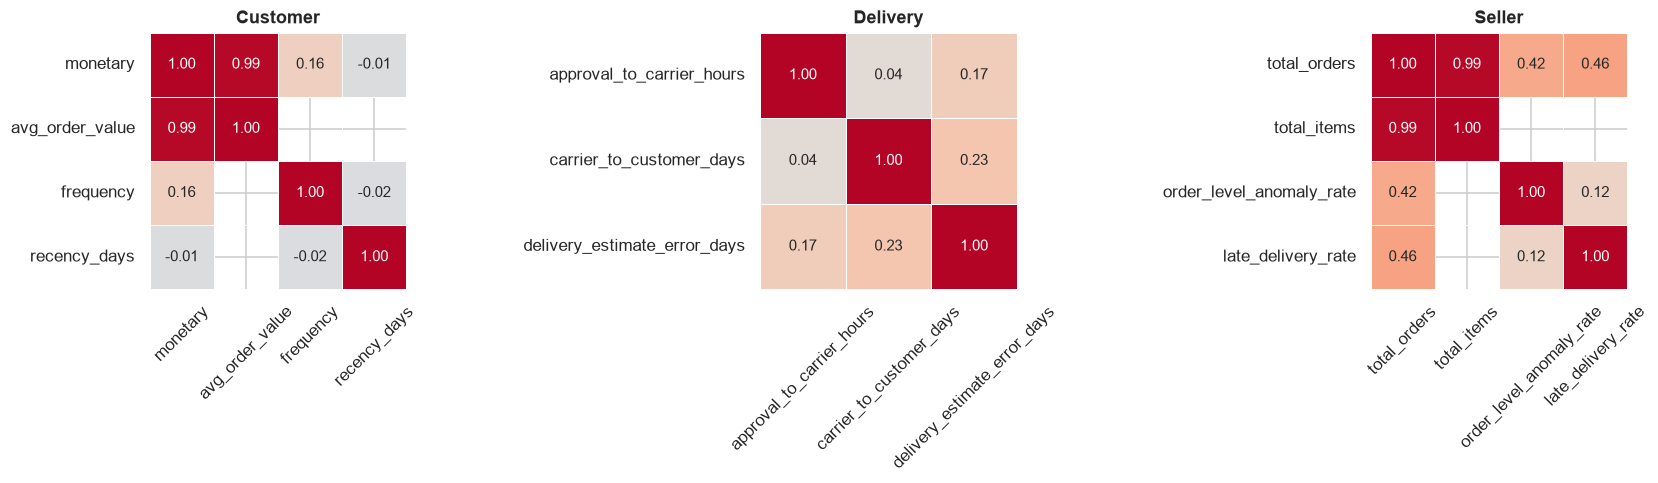

In [61]:
# Three small domain heatmaps in one figure, built directly from the pairwise
# results above - not from a full .corr() call, which would pull in every
# column and defeat the purpose of a curated set. The three domains span
# different grains (customer, order, seller) and cannot be combined into one
# matrix; this stays honest about that rather than forcing a single grid.
def build_domain_matrix(variables, results):

    matrix = pd.DataFrame(
        np.nan,
        index=variables,
        columns=variables,
        dtype=float
    )

    # correlation of variable with itself
    for v in variables:
        matrix.loc[v, v] = 1.0

    for _, row in results.iterrows():

        a = row["Variable A"]
        b = row["Variable B"]

        if a in variables and b in variables:
            matrix.loc[a, b] = row["Spearman rho"]
            matrix.loc[b, a] = row["Spearman rho"]

    return matrix


domains = {
    "Customer": ["monetary", "avg_order_value", "frequency", "recency_days"],
    "Delivery": ["approval_to_carrier_hours", "carrier_to_customer_days", "delivery_estimate_error_days"],
    "Seller": ["total_orders", "total_items", "order_level_anomaly_rate", "late_delivery_rate"],
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (title, variables) in zip(axes, domains.items()):
    matrix = build_domain_matrix(variables, correlation_table)
    sns.heatmap(
        matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
        square=True, cbar=False, ax=ax, linewidths=0.5,
    )
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Reading the heatmap

Each panel covers one business domain only — the three cannot be merged into a single matrix,
because a seller-level rate and a customer-level spend figure describe different units of
observation and are not meaningfully correlated row-for-row.

- **Diagonal cells (always 1.0)** are a variable against itself — a formatting artefact, not a finding.
- **Darker red** marks a strong positive relationship; **darker blue** marks a strong negative one.
- **Blank cells** are pairs not computed in this curated set, not zero correlation.
- Every value shown is a Spearman coefficient unless the earlier printout confirmed a Pearson pair — check the tidy table above for which one applies to a specific cell.

In [62]:
redundancy_table = correlation_table[correlation_table["Spearman rho"].abs()>=REDUNDANCY_RHO_THRESHOLD]
[["Variable A", "Variable B", "Spearman rho", "Note"]].copy()

interpretations = {
("monetary", "avg_order_value"): "Anticipated during warehouse design: with ~97% of customers "
"buying once (S9), avg_order_value = monetary / 1 for almost everyone - this confirms it numerically.",
("total_orders", "total_items"): "Expected: an order's item count and a seller's order count "
    "move together by the nature of what they count.",
}

redundancy_table["Interpretation"] = redundancy_table.apply(
    lambda r: interpretations.get(
    (r["Variable A"], r["Variable B"]),
    "Elevated correlation - treat as one signal, not two, in Notebook 02 (see Note column for context).",
    ),
    axis=1,
)

redundancy_table

,Domain,Variable A,Variable B,N,Spearman rho,Direction,Strength,Note,Interpretation
0,Customer,monetary,avg_order_value,94989,0.9870,Positive,Strong (potential redundancy),Potential redundancy check,Anticipated during warehouse design: with ~97%...
7,Seller,total_orders,total_items,3095,0.9870,Positive,Strong (potential redundancy),Potential redundancy check,Expected: an order's item count and a seller's...


Strong correlations are treated as potential redundancy, not as independent evidence. Structurally expected relationships such as monetary–avg_order_value and total_orders–total_items are not interpreted as new business findings.

Variables showing strong correlation will not automatically be removed; Notebook 02 will avoid presenting redundant measures as separate evidence. Correlation is descriptive and does not establish causation.

## S15. Seller Rate Reliability & Minimum Volume Assessment

Seller rates can be unstable at low volume (e.g., 1 late order out of 2 = 50%). This section selects a common minimum-volume rule for seller-rate analysis.

**Scope:** `order_level_anomaly_rate` and `late_delivery_rate`, using delivered-order volume as the practical reliability measure.

**Selection principle:** evaluate a small set of sensible thresholds and choose the smallest one that retains at least **90% of delivered order volume** in the reliable seller group.


### Evaluating candidate thresholds

**The selection rule, stated before any candidate is scored:** choose the **smallest** minimum
delivered-order threshold, among the candidates evaluated, that still leaves **at least 90% of
total delivered order volume** covered by sellers who clear it. Ninety percent is a practical
business bar — high enough that the reliable-seller group still represents the overwhelming
majority of real transaction volume, not a narrow slice of only the biggest sellers.

Four candidates are evaluated: 5, 10, 20, and 30 delivered orders.

In [72]:
def evaluate_threshold(min_orders):
    reliable = sellers["delivered_order_count"] >= min_orders
    total_delivered_volume = sellers["delivered_order_count"].sum()
    reliable_delivered_volume = sellers.loc[reliable, "delivered_order_count"].sum()
    
    return {
        "Min delivered orders": min_orders,
        "Sellers retained": int(reliable.sum()),
        "% of sellers": round(reliable.mean() * 100, 1),
        "% of delivered order volume retained":round(reliable_delivered_volume/total_delivered_volume*100, 1),
    }


threshold_candidates = [0,1,2,5, 10, 20, 30]
threshold_evaluation = pd.DataFrame([evaluate_threshold(t) for t in threshold_candidates])
threshold_evaluation

,Min delivered orders,Sellers retained,% of sellers,% of delivered order volume retained
0,0,3095,100.0000,100.0000
1,1,2970,96.0000,100.0000
2,2,2435,78.7000,99.5000
3,5,1766,57.1000,97.6000
4,10,1237,40.0000,93.9000
5,20,804,26.0000,87.8000
6,30,627,20.3000,83.5000


In [64]:
# Apply the pre-stated rule: smallest candidate that retains >= 90% of volume.
qualifying = threshold_evaluation[threshold_evaluation["% of delivered order volume retained"] >= 90]

if qualifying.empty:
    raise ValueError(
        "None of the candidate thresholds retains at least 90% "
        "of delivered-order volume. Review the candidate thresholds."
    )

RELIABLE_SELLER_THRESHOLD = int(qualifying["Min delivered orders"].min())

sellers["is_reliable_seller"] = sellers["delivered_order_count"] >= RELIABLE_SELLER_THRESHOLD

print(f"Selected threshold: {RELIABLE_SELLER_THRESHOLD} delivered orders")
print(f"Reliable sellers   : {sellers['is_reliable_seller'].sum():,} of {len(sellers):,} "
      f"({sellers['is_reliable_seller'].mean() * 100:.1f}%)")
print(f"Order volume covered: "
      f"{sellers.loc[sellers['is_reliable_seller'], 'delivered_order_count'].sum() / sellers['delivered_order_count'].sum() * 100:.1f}%")

Selected threshold: 5 delivered orders
Reliable sellers   : 1,766 of 3,095 (57.1%)
Order volume covered: 97.6%


### Revisiting S14: order_level_anomaly_rate ↔ late_delivery_rate on reliable sellers only

S14 computed this correlation across every seller and labelled it preliminary. Here it is
recomputed on the reliable subset only, using the same method S14 used — Spearman, since S12
found neither rate variable symmetric — so the two figures are directly comparable.

In [65]:
full_population_rho = correlation_table.loc[
    (correlation_table["Variable A"] == "order_level_anomaly_rate")
    & (correlation_table["Variable B"] == "late_delivery_rate"),
    "Spearman rho",
].iloc[0]

reliable_subset = sellers.loc[sellers["is_reliable_seller"]]
reliable_rho = stats.spearmanr(
    reliable_subset["order_level_anomaly_rate"], reliable_subset["late_delivery_rate"]
).correlation

reliability_comparison = pd.DataFrame(
    [
        ["Full seller population (S14)", len(sellers), round(full_population_rho, 3)],
        ["Reliable sellers only (S15)", len(reliable_subset), round(reliable_rho, 3)],
    ],
    columns=["Population", "N sellers", "Spearman correlation"],
)

reliability_comparison

,Population,N sellers,Spearman correlation
0,Full seller population (S14),3095,0.1250
1,Reliable sellers only (S15),1766,-0.0420


### Decision

A minimum seller-volume threshold is required because rates based on very few orders can be unstable.
The threshold is selected as the smallest candidate that retains at least 90% of delivered-order volume.
Sellers below this threshold are not removed. They remain in the dataset but are treated as lower-confidence observations for seller-rate comparisons.
is_reliable_seller is used in later seller-level rate analysis.
The S14 correlation between order_level_anomaly_rate and late_delivery_rate is rechecked on reliable sellers to determine whether the relationship persists after reducing low-volume noise.
No business conclusion is made from the threshold itself. It is an analytical reliability rule.

## S16. Notebook 02 Analysis Contract

Notebook 01 has established the populations, restrictions and methods for Notebook 02. These rules are fixed before interpreting the results.

| Comparison | Population | Method | Primary metric / output |
|---|---|---|---|
| Repeat rate by first-purchase category | Customers with known category | Chi-square with Monte Carlo p-value | Repeat-buyer rate |
| New vs. established seller anomaly rate | Reliable sellers | Distribution/rate comparison | Anomaly rate |
| Anomaly rate vs. late-delivery rate | Reliable sellers | Spearman correlation | ρ |
| Cross-state vs. same-state delivery duration | Delivered orders with known duration | Rank-based comparison | Median duration |
| Fulfillment anomaly vs. review score | Reviewed orders | Rank-based comparison | Review-score distribution/median |
| Anomaly severity vs. review score | Reviewed orders | Descriptive/exploratory comparison | Review-score distribution/median |
| Lateness bucket vs. review score | Reviewed and delivered orders | Rank-based comparison | Review-score distribution/median |
| Repeat vs. one-time buyer value | Customers with purchases | Distribution comparison | Median monetary / AOV |

### Reporting rules

- Report **counts with percentages/rates** for small or rare groups.
- Lead with the **median** for skewed variables.
- State the **population/restriction** for every result.
- Treat correlations as **association/co-movement, not causation**.
- Treat `monetary` and `avg_order_value`, as overlapping measures rather than independent evidence.
- Interpret `seller anomaly rate` and `late-delivery rate` together, not as two independent confirmations.
- Label thin or sparse groups as exploratory.
- Do not remove statistical outliers unless there is a separate data-quality reason.

**Freeze:** Notebook 02 follows these rules without changing the method or population after seeing the results.

## S17. Notebook 01 Summary & Handoff

### What Notebook 01 established

- **Data quality**: validated grain, keys, missingness, duplicates, data types and measurement scales.
- **Time scope**: identified the valid analysis period for trend analysis.
- **Descriptive profile**: established distributions, concentration, skew, outliers and numerical relationships.
- **Data-quality interpretation**: retained legitimate extreme values and documented known anomalies rather than deleting rows.
- **Seller reliability**: established `is_reliable_seller` using the pre-defined minimum-volume approach.
- **Analysis contract**: fixed the populations, methods and reporting rules for Notebook 02.

### Notebook 02 focus

Notebook 02 will analyse four business areas:

1. **Seller Performance & Risk**
2. **Delivery & Operations Reliability**
3. **Customer Experience & Satisfaction**
4. **Customer Value & Retention**

Notebook 02 will use the approved comparisons in S16 and will not re-profile the data or change the methodology after seeing the results.

### Datasets

| Dataset | Grain | Main use |
|---|---|---|
| `seller_features` | One row per seller | Seller risk and reliability |
| `order_delivery_features` | One row per order | Delivery duration and on-time performance |
| `order_experience_features` | One row per order | Review and fulfillment experience |
| `customer_rfm_features` | One row per customer | Customer value and repeat behaviour |

### Key restrictions
- **Statistical outliers** are retained, not automatically removed.
- `review_score` is ordinal; use distributions/medians rather than treating it as continuous.
- `frequency` is near-degenerate; use `is_repeat_buyer` for repeat-purchase analysis.
- **Seller-rate analysis** uses the reliable-seller population.
- **Small/sparse groups** are reported as exploratory rather than over-interpreted.
- `monetary` / `avg_order_value` and seller risk rates are interpreted as overlapping evidence where appropriate.

### Final handoff

Notebook 01 is complete. Notebook 02 can now focus on answering the business questions using the frozen analytical rules in S16.

In [68]:
rfm["first_order_date"] = pd.to_datetime(rfm["first_order_date"])
rfm["last_order_date"] = pd.to_datetime(rfm["last_order_date"])

rfm.to_parquet(
    DATA_DIR / "customer_rfm_features.parquet",
    engine="pyarrow",
    index=False
)

print("RFM parquet rewritten successfully.")
print(rfm[["first_order_date", "last_order_date"]].dtypes)

RFM parquet rewritten successfully.
first_order_date    datetime64[s]
last_order_date     datetime64[s]
dtype: object


In [69]:
test = pd.read_parquet(
    DATA_DIR / "customer_rfm_features.parquet",
    engine="pyarrow"
)

print(test.shape)
print(test[["first_order_date", "last_order_date"]].dtypes)

(94989, 15)
first_order_date    datetime64[ms]
last_order_date     datetime64[ms]
dtype: object
